# Week 2 — Feature Engineering: Airline Passenger Satisfaction

**Course:** MSc Machine Learning · **Team:** Group 1 — Team 22

**Data:** `data/raw/airline_passenger_satisfaction.csv` — `129,880 × 24` → 22 features + target `Satisfaction` (`Satisfied` → 1, `Neutral or Dissatisfied` → 0)

**Protocol:** `random_state=42` everywhere · stratified 80/20 split · 5-fold `StratifiedKFold` · primary metric ROC-AUC (+ PR-AUC, F1)

## 1. Team & Roles

| Member | Student ID | Role |
|---|---|---|
| Alisher Toxanbayev | 26MD0376 | Feature Engineer |
| Arsen Zhexenbiyev | 22MD0361 | Modelling Lead & Deployment Lead *(merged per 3-member team guidelines)* |
| Kamila Muzanbekova | 26MD0368 | Report Lead |

## 2. Feature Summary Table

The table covers all **24 raw columns** and the **engineered features**, and is placed before any modelling code. Each row has a decision from `{keep, transform, encode, remove, create, target}`, the `ColumnTransformer` branch that does the work, and the reason for this dataset. Level shares are from the full CSV. All fitted statistics (medians, scalers, variance filter) are learned on `X_train` only, inside the pipeline. The numeric `X_train` profile (skew, zero %, NaN) is printed in §3, right after the split.

### 2.1 Raw columns (24)

| # | Feature | Type / domain | Decision | CT branch → implementation | Output column(s) | Justification (this dataset) |
|---|---|---|---|---|---|---|
| 1 | `ID` | Integer, unique per row | **Remove** | Dropped before the split | — | Row key with no predictive signal; keeping it would let the model memorise rows |
| 2 | `Satisfaction` | Binary string: `Neutral or Dissatisfied` 56.55% / `Satisfied` 43.45% | **Target** | Stateless map `Satisfied → 1`, else `0`, before the split | `y` | Mild imbalance → stratified 80/20 split and PR-AUC reported alongside ROC-AUC |
| 3 | `Gender` | Nominal: `Female` 50.7% / `Male` 49.3% | **Encode** | `nominal` → `OneHotEncoder(drop="first", handle_unknown="ignore")` | `Gender_Male` † | Balanced binary; `drop="first"` avoids the dummy trap in LR |
| 4 | `Customer Type` | Nominal: `Returning` 81.7% / `First-time` 18.3% | **Encode** | `nominal` (as above) | `Customer Type_Returning` | Loyalty is a plausible satisfaction driver; the smallest level is well above 1% |
| 5 | `Type of Travel` | Nominal: `Business` 69.1% / `Personal` 30.9% | **Encode** | `nominal` (as above) | `Type of Travel_Personal` | Kept as one named column so SQ2 (business vs personal drivers) can be read from SHAP |
| 6 | `Class` | Ordinal: `Economy` 44.9% / `Economy Plus` 7.2% / `Business` 47.9% | **Encode** | `class_ord` → `OrdinalEncoder([["Economy","Economy Plus","Business"]], unknown_value=-1)` | `Class` (0/1/2) | Service tiers are ordered; one column keeps the order without three dummies |
| 7 | `Age` | Continuous, symmetric (skew ≈ 0.00) | **Keep** | `age` → median `SimpleImputer` → `RobustScaler` | `Age` † | Not skewed, so no transform; scaled so LR coefficients are comparable |
| 8 | `Flight Distance` | Continuous > 0, right-skewed (skew 1.11, min 31, no zeros) | **Transform** | `log_skewed` → median `SimpleImputer` → `log1p` → `RobustScaler` | `log1p_Flight Distance` † | Compresses the long-haul tail; LR is linear in x |
| 9 | `Departure Delay` | Minutes ≥ 0, heavy tail (skew 6.83, 56.5% zeros) | **Transform** (+ feeds row 25) | `log_skewed` (as above) | `log1p_Departure Delay` | `log1p` compresses the tail and keeps exact zeros at 0; the delay effect on log-odds is concave |
| 10 | `Arrival Delay` | Minutes ≥ 0; the only column with NaNs (321 in `X_train`, 0.31%); r = 0.966 with `Departure Delay` | **Remove** (raw) → feeds row 25 | Consumed by `net_delay`; no raw output | — | The only pair with \|r\| > 0.90; dropping the raw column removes the redundancy and keeps the information |
| 11 | `Departure and Arrival Time Convenience` | Likert 0–5 (`0` = not applicable) | **Keep** | `likert` → median `SimpleImputer` → `RobustScaler` | same name | Scheduling touchpoint; the 0-rate is above 1%, so its flag survives (row 27) |
| 12 | `Ease of Online Booking` | Likert 0–5 | **Keep** | `likert` | same name | Digital touchpoint; r = 0.715 with Wifi (below 0.90), so both stay and selection decides |
| 13 | `Check-in Service` | Likert 0–5 | **Keep** | `likert` | same name | Ground-service touchpoint; no 0s in train, so its flag is constant and dropped |
| 14 | `Online Boarding` | Likert 0–5 | **Keep** | `likert` | same name | Digital touchpoint; expected strong signal; its flag survives |
| 15 | `Gate Location` | Likert 0–5 | **Keep** | `likert` | same name | Airport-layout touchpoint; its flag is constant on train and dropped |
| 16 | `On-board Service` | Likert 0–5 | **Keep** | `likert` | same name | Cabin-crew touchpoint |
| 17 | `Seat Comfort` | Likert 0–5 | **Keep** | `likert` | same name † | Comfort touchpoint; r 0.61–0.69 with Cleanliness (kept, RFECV candidate); its flag is constant on train and dropped |
| 18 | `Leg Room Service` | Likert 0–5 | **Keep** | `likert` | same name | Comfort touchpoint, likely tied to `Class` |
| 19 | `Cleanliness` | Likert 0–5 | **Keep** | `likert` | same name | r 0.61–0.69 with Entertainment and Seat Comfort; below threshold, so kept |
| 20 | `Food and Drink` | Likert 0–5 | **Keep** | `likert` | same name † | Catering touchpoint |
| 21 | `In-flight Service` | Likert 0–5 | **Keep** | `likert` | same name | Cabin-crew touchpoint |
| 22 | `In-flight Wifi Service` | Likert 0–5 | **Keep** | `likert` | same name | Digital touchpoint; a 0 often means wifi was not offered, so its flag survives |
| 23 | `In-flight Entertainment` | Likert 0–5 | **Keep** | `likert` | same name | Comfort touchpoint; correlated with Cleanliness (0.61–0.69, kept) |
| 24 | `Baggage Handling` | Likert 0–5 | **Keep** | `likert` | same name | Ground-service touchpoint; its flag is constant on train and dropped |

*Likert note:* the 14 ratings are ordinal scores, so they stay numeric (no one-hot). The median imputer is defensive, since none has NaNs. `0` means *not applicable*, not a low rating, so row 27 handles it separately.

### 2.2 Engineered features

| # | Feature | Type | Decision | CT branch → implementation | Output | Justification (this dataset) |
|---|---|---|---|---|---|---|
| 25 | `Net Delay Recovery` | Continuous; `Departure Delay − Arrival Delay` (minutes recovered in flight; skew −2.92, can be negative) | **Create** | `net_delay` → `DelayFeatureEngineer(impute_strategy="net_median")` → `PowerTransformer("yeo-johnson", standardize=False)` → `RobustScaler` | `Net Delay Recovery` † | Resolves r = 0.966 and keeps the recovery signal. A missing `Arrival Delay` gets the **train median of the difference**, not of arrival (see deviation 4). Yeo-Johnson, unlike Box-Cox, accepts negative values |
| 26 | `log1p_Flight Distance`, `log1p_Departure Delay` | Continuous | **Transform** (rows 8–9) | `FunctionTransformer(np.log1p, feature_names_out=log1p_names)` | 2 cols | Stateless, so it cannot leak; the name function is defined at module level so `joblib` can pickle it |
| 27 | `<Likert>_is_na` × 14 | Binary float `(x == 0)` | **Create** + filter | `likert_flags` → `LikertZeroFlagger` → `VarianceThreshold(0.0099)` | **4 kept:** `Departure and Arrival Time Convenience_is_na`, `Ease of Online Booking_is_na`, `In-flight Wifi Service_is_na`, `Online Boarding_is_na` | Gives "not used" rows their own intercept, so each rating's slope is fit on real 1–5 scores. The threshold 0.0099 = p(1−p) at p = 1%: below about 1,000 positives in train, LR coefficients are unstable. **10 flags removed:** 4 are constant on train (`Check-in Service`, `Gate Location`, `Seat Comfort`, `Baggage Handling`) and 6 have prevalence < 1% (`On-board Service`, `Leg Room Service`, `Cleanliness`, `Food and Drink`, `In-flight Service`, `In-flight Entertainment`). The per-flag evidence is in §5 |

**Width:** 22 columns before selection (3 OHE + 1 ordinal + 1 age + 2 log + 1 net delay + 14 Likert), plus 4 flags = **26 columns** (S4). §9 reduces this to **≤ 20**, so predictive PCA is not needed (§10).

† *Built by the preprocessor but **not used by the final model**:* §9 keeps 20 of the 26 columns, and `CappedRFECV` drops these six (`Gender_Male`, `Age`, `log1p_Flight Distance`, `Seat Comfort`, `Food and Drink`, `Net Delay Recovery`; full list in §11). The only delay signal the final LR sees is `log1p_Departure Delay`. **Week 4 app:** the fitted pipeline still validates and transforms all 22 raw columns before selection, so the app must collect every raw input, including `Arrival Delay` (NaN allowed), `Gender` and `Age`, even though the final model does not use them.

### 2.3 Deviations from the Week 1 proposal

| # | Week 1 proposal | Week 2 (this notebook) | Reason |
|---|---|---|---|
| 1 | 23 input features | **22 features** | `ID` is a key and `Satisfaction` is the target: 24 − 2 = 22 |
| 2 | Likert block assumed > 0.90 collinear | **Not collinear**: the highest Likert pair is r = 0.715 (Ease of Booking ↔ Wifi) | Measured on `X_train`; all Likert columns kept, selection decides |
| 3 | `Flight Distance` treated as zero-inflated | **Skewed but not zero-inflated** (min 31) | Plain `log1p`, no zero-indicator |
| 4 | Impute `Arrival Delay` with its raw median | **Impute the net difference** with its train median (`net_median`) | Both medians are 0, but 83 of the 321 NaN-arrival train rows have `Departure Delay > 54`. Arrival-median imputation would give them up to +530 min recovery, far above the observed train max of +54. Tested in S1 vs S1b |
| 5 | Keep all 14 `*_is_na` flags | **Only 4 of 14 survive** `VarianceThreshold(0.0099)` | 10 are constant or < 1% prevalent on train (row 27) |
| 6 | Default `LogisticRegression()` | `LogisticRegression(max_iter=1000, random_state=42)` | Safety margin only: the default `max_iter=100` also converged in our runs on S0 and S4 |
| 7 | PCA / UMAP considered for modelling | **t-SNE for visualisation only**; no PCA or UMAP in the predictive pipeline | N_final ≤ 20 keeps named features for SQ2 SHAP; `umap-learn` is not installed |

## 3. Setup, Load, Split & `X_train` Numeric Profile

In [1]:
# Cell 1 — paths, imports & constants
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import train_test_split

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
DATA_PATH = ROOT / "data" / "raw" / "airline_passenger_satisfaction.csv"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Fallback: use the CSV at the repo root if data/raw/ does not exist
if not DATA_PATH.exists() and (ROOT / DATA_PATH.name).exists():
    DATA_PATH = ROOT / DATA_PATH.name
    print(f"NOTE: data/raw/ not found, using legacy location {DATA_PATH}")

RANDOM_STATE = 42
TARGET = "Satisfaction"

CLASS_ORDER = ["Economy", "Economy Plus", "Business"]
NOMINAL_COLS = ["Gender", "Customer Type", "Type of Travel"]
ORDINAL_COLS = ["Class"]
CATEGORICAL_COLS = NOMINAL_COLS + ORDINAL_COLS
CAT_DOMAINS = {
    "Gender": {"Female", "Male"},
    "Customer Type": {"First-time", "Returning"},
    "Type of Travel": {"Business", "Personal"},
    "Class": set(CLASS_ORDER),
}
CONTINUOUS_COLS = ["Age", "Flight Distance", "Departure Delay", "Arrival Delay"]
LIKERT_COLS = [
    "Departure and Arrival Time Convenience", "Ease of Online Booking", "Check-in Service",
    "Online Boarding", "Gate Location", "On-board Service", "Seat Comfort",
    "Leg Room Service", "Cleanliness", "Food and Drink", "In-flight Service",
    "In-flight Wifi Service", "In-flight Entertainment", "Baggage Handling",
]
NUMERIC_COLS = CONTINUOUS_COLS + LIKERT_COLS  # 18 numerics
# The 22 raw features in CSV order (ID and Satisfaction removed)
FEATURE_COLS = [
    "Gender", "Age", "Customer Type", "Type of Travel", "Class",
    "Flight Distance", "Departure Delay", "Arrival Delay", *LIKERT_COLS,
]
assert len(FEATURE_COLS) == 22 and len(LIKERT_COLS) == 14 and len(NUMERIC_COLS) == 18

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

print(f"ROOT      : {ROOT}")
print(f"DATA_PATH : {DATA_PATH}")
print(f"FIG_DIR   : {FIG_DIR}")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__} | seaborn {sns.__version__}")

ROOT      : C:\Users\Kamila\Desktop\Airline Passenger Sat\ML-project
DATA_PATH : C:\Users\Kamila\Desktop\Airline Passenger Sat\ML-project\data\raw\airline_passenger_satisfaction.csv
FIG_DIR   : C:\Users\Kamila\Desktop\Airline Passenger Sat\ML-project\reports\figures
Python 3.14.6 | numpy 2.4.6 | pandas 3.0.3 | scikit-learn 1.9.0 | matplotlib 3.11.0 | seaborn 0.13.2


In [2]:
# Load the raw CSV, drop the ID key and map the target (stateless, so safe before the split)
df = pd.read_csv(DATA_PATH)
assert df.shape == (129_880, 24), f"unexpected shape {df.shape}"
assert df["ID"].is_unique, "ID is not a unique key"
assert set(df[TARGET].unique()) == {"Satisfied", "Neutral or Dissatisfied"}, "unexpected target labels"

X = df.drop(columns=["ID", TARGET])
y = (df[TARGET] == "Satisfied").astype(int).rename(TARGET)

print(f"Raw CSV : {df.shape[0]:,} rows x {df.shape[1]} columns")
print(f"X       : {X.shape[0]:,} rows x {X.shape[1]} features | y positive rate (Satisfied) = {y.mean():.4f}")

Raw CSV : 129,880 rows x 24 columns
X       : 129,880 rows x 22 features | y positive rate (Satisfied) = 0.4345


In [3]:
# Pre-split schema check on raw X. Stateless: it reads no statistics, so it
# cannot leak. The same function is reused by the Week 4 app to validate user input.
def validate_raw_features(X: pd.DataFrame) -> None:
    """Assert the 22-column order, known categorical domains, Likert in {0..5}, NaNs only in Arrival Delay."""
    assert list(X.columns) == FEATURE_COLS, (
        f"column order mismatch: {[c for c in X.columns if c not in FEATURE_COLS] or list(X.columns)}"
    )
    for col, domain in CAT_DOMAINS.items():
        unknown = set(X[col].dropna().unique()) - domain
        assert not unknown, f"{col}: unknown levels {sorted(unknown)}"
    for col in NUMERIC_COLS:
        assert pd.api.types.is_numeric_dtype(X[col]), f"{col} is not numeric ({X[col].dtype})"
    for col in LIKERT_COLS:
        vals = X[col].dropna()
        assert vals.isin(range(6)).all(), f"{col}: values outside {{0..5}}: {sorted(set(vals) - set(range(6)))}"
    nan_cols = X.columns[X.isna().any()].tolist()
    assert set(nan_cols) <= {"Arrival Delay"}, f"unexpected NaNs in {sorted(set(nan_cols) - {'Arrival Delay'})}"


validate_raw_features(X)
print("Schema check passed:")
print(f"  - 22 columns in the expected order")
print(f"  - categorical domains: " + "; ".join(f"{c} = {sorted(d)}" for c, d in CAT_DOMAINS.items()))
print(f"  - 14 Likert columns, all values in {{0..5}}")
print(f"  - NaNs only in: {X.columns[X.isna().any()].tolist()}")

Schema check passed:
  - 22 columns in the expected order
  - categorical domains: Gender = ['Female', 'Male']; Customer Type = ['First-time', 'Returning']; Type of Travel = ['Business', 'Personal']; Class = ['Business', 'Economy', 'Economy Plus']
  - 14 Likert columns, all values in {0..5}
  - NaNs only in: ['Arrival Delay']


In [4]:
# Split FIRST: every statistic, plot and fit below uses X_train only; X_test is touched only in §13
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
assert (len(X_train), len(X_test)) == (103_904, 25_976)
assert X_train.index.intersection(X_test.index).empty

# Drop the full-data objects so no later cell can compute a statistic on them by accident
del df, X, y

print(f"X_train {X_train.shape} | X_test {X_test.shape}")
print(f"Positive rate (Satisfied): train {y_train.mean():.4f} | test {y_test.mean():.4f}")

X_train (103904, 22) | X_test (25976, 22)
Positive rate (Satisfied): train 0.4345 | test 0.4345


In [5]:
# X_train numeric profile: skew, zero %, NaN (feeds the Feature Summary Table in §2)
num_train = X_train[NUMERIC_COLS]
profile = pd.DataFrame({
    "block": ["continuous"] * len(CONTINUOUS_COLS) + ["likert"] * len(LIKERT_COLS),
    "min": num_train.min(),
    "median": num_train.median(),
    "mean": num_train.mean(),
    "max": num_train.max(),
    "std": num_train.std(),
    "skew": num_train.skew(),
    "zero %": num_train.eq(0).mean() * 100,
    "NaN": num_train.isna().sum(),
    "NaN %": num_train.isna().mean() * 100,
})
display(profile.round({"median": 2, "mean": 2, "std": 2, "skew": 2, "zero %": 2, "NaN %": 2}))

assert profile.loc[profile["NaN"] > 0].index.tolist() == ["Arrival Delay"]
assert profile.loc["Flight Distance", "min"] > 0, "Flight Distance has zeros (not expected)"
print(f"NaN in Arrival Delay: {profile.loc['Arrival Delay', 'NaN']:,} rows "
      f"({profile.loc['Arrival Delay', 'NaN %']:.2f}% of X_train)")
print(f"Flight Distance: min {profile.loc['Flight Distance', 'min']:.0f}, "
      f"skew {profile.loc['Flight Distance', 'skew']:.2f} -> skewed but not zero-inflated")
print(f"Departure Delay: skew {profile.loc['Departure Delay', 'skew']:.2f}, "
      f"{profile.loc['Departure Delay', 'zero %']:.1f}% zeros")
print(f"Age: skew {profile.loc['Age', 'skew']:.2f}")

,block,min,median,mean,max,std,skew,zero %,NaN,NaN %
Age,continuous,7.0,40.0,39.40,85.0,15.15,-0.00,0.00,0,0.00
Flight Distance,continuous,31.0,844.0,1190.50,4983.0,998.04,1.11,0.00,0,0.00
Departure Delay,continuous,0.0,0.0,14.72,1592.0,38.24,6.83,56.48,0,0.00
Arrival Delay,continuous,0.0,0.0,15.08,1584.0,38.61,6.70,56.04,321,0.31
Departure and Arrival Time Convenience,likert,0.0,3.0,3.06,5.0,1.53,-0.34,5.17,0,0.00
Ease of Online Booking,likert,0.0,3.0,2.76,5.0,1.40,-0.02,4.37,0,0.00
Check-in Service,likert,1.0,3.0,3.31,5.0,1.27,-0.37,0.00,0,0.00
Online Boarding,likert,0.0,3.0,3.25,5.0,1.35,-0.46,2.39,0,0.00
Gate Location,likert,1.0,3.0,2.98,5.0,1.28,-0.06,0.00,0,0.00
On-board Service,likert,0.0,4.0,3.38,5.0,1.29,-0.42,0.00,0,0.00


NaN in Arrival Delay: 321 rows (0.31% of X_train)
Flight Distance: min 31, skew 1.11 -> skewed but not zero-inflated
Departure Delay: skew 6.83, 56.5% zeros
Age: skew -0.00


## 4. Custom Transformers & Verification

In [6]:
# 4a. Import the canonical package and show the custom-transformer source (it lives in
# src/airline_fe/ so the Week 4 app can joblib.load the fitted pipeline).
import inspect
import io
import warnings

import joblib
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

import airline_fe.config as cfg
from airline_fe.transformers import DelayFeatureEngineer, LikertZeroFlagger
from airline_fe.pipeline import (build_preprocessor, build_pipeline, log1p_names, _numeric,
                                 STEP_KW, EXPECTED_WIDTH)
from airline_fe.evaluation import (CV, AblationLog, CappedRFECV, coef_std_across_folds,
                                   discrete_mask, make_mi_score_func, make_selectkbest_search,
                                   one_std_refit, pick_winner, selected_features,
                                   selection_frequency, jaccard)

# The notebook's local column lists must match the package config exactly (no drift)
assert cfg.LIKERT == LIKERT_COLS and cfg.NOMINAL == NOMINAL_COLS and cfg.ORDINAL == ORDINAL_COLS
assert cfg.CLASS_ORDER == [CLASS_ORDER] and cfg.RANDOM_STATE == RANDOM_STATE
print("Notebook constants match src/airline_fe/config.py\n")

for obj in (DelayFeatureEngineer, LikertZeroFlagger, log1p_names, _numeric, build_preprocessor,
            build_pipeline):
    print(f"# {'=' * 20} {obj.__module__}.{obj.__name__} {'=' * 20}")
    print(inspect.getsource(obj))

Notebook constants match src/airline_fe/config.py

# ==================== airline_fe.transformers.DelayFeatureEngineer ====================
class DelayFeatureEngineer(BaseEstimator, TransformerMixin):
    """Create net delay recovery while learning imputation on fit data only.

    Input order is departure delay, then arrival delay. For missing arrival
    values, ``net_median`` imputes the net delay directly; ``arrival_median``
    imputes arrival delay before subtraction.
    """

    def __init__(self, impute_strategy="net_median"):
        self.impute_strategy = impute_strategy

    def fit(self, X, y=None):
        if self.impute_strategy not in {"net_median", "arrival_median"}:
            raise ValueError(
                "impute_strategy must be 'net_median' or 'arrival_median'."
            )
        values = _as_2d_array(X, 2, self.__class__.__name__)
        departure, arrival = values[:, 0], values[:, 1]
        valid_net = np.isfinite(departure) & np.isfinite(arrival)
    

In [7]:
# 4b. Verification (spec §2.5): one assert cell, on X_train only, using clone()s of the templates
# 1. clone() / get_params() round-trip for each custom class
for tmpl in (DelayFeatureEngineer(impute_strategy="arrival_median"), LikertZeroFlagger(na_value=0),
             CappedRFECV(LogisticRegression(max_iter=1000), max_features=17)):
    twin = clone(tmpl)
    assert twin is not tmpl and twin.get_params().keys() == tmpl.get_params().keys()
    assert all(repr(twin.get_params()[k]) == repr(v) for k, v in tmpl.get_params().items())
print("1. clone()/get_params() round-trip OK for DelayFeatureEngineer, LikertZeroFlagger, CappedRFECV")

# 2. Fit on X_train.iloc[1000:], transform X_train.iloc[:1000]: fitted state must not change
pre = Pipeline([("preprocess", clone(build_preprocessor()))]).fit(X_train.iloc[1000:])
net_step = pre.named_steps["preprocess"].named_transformers_["net_delay"].named_steps["net"]
state_before = (net_step.median_net_, net_step.median_arrival_, net_step.median_departure_)
Z_head = pre.transform(X_train.iloc[:1000])
assert (net_step.median_net_, net_step.median_arrival_, net_step.median_departure_) == state_before
print(f"2. No refit on transform: median_net_={state_before[0]}, median_arrival_={state_before[1]}, "
      f"median_departure_={state_before[2]} unchanged")

# 3. Width = len(get_feature_names_out()), float64, no NaN/inf (default = S4 configuration)
names = pre.named_steps["preprocess"].get_feature_names_out()
assert Z_head.shape[1] == len(names) == EXPECTED_WIDTH["S4"] == 26
assert list(Z_head.columns) == list(names) and len(set(names)) == len(names)
assert (Z_head.dtypes == "float64").all() and np.isfinite(Z_head.to_numpy()).all()
print(f"3. Output {Z_head.shape}, float64, no NaN/inf, names match get_feature_names_out()")

# 4. Hand-built 5-row frame: normal, NaN arrival, NaN departure, both NaN, negative recovery
toy = pd.DataFrame([[10.0, 5.0], [4.0, np.nan], [np.nan, 3.0], [np.nan, np.nan], [5.0, 20.0]],
                   columns=cfg.DELAY_PAIR)
# Fitted on toy itself: median_net_ = median(5, -15) = -5, median_arrival_ = median(5, 3, 20) = 5,
# median_departure_ = median(10, 4, 5) = 5
toy_net = Pipeline([("net", DelayFeatureEngineer())]).fit(toy).transform(toy).ravel()
toy_arr = Pipeline([("net", DelayFeatureEngineer("arrival_median"))]).fit(toy).transform(toy).ravel()
assert np.allclose(toy_net, [5.0, -5.0, 2.0, -5.0, -15.0]), toy_net
assert np.allclose(toy_arr, [5.0, -1.0, 2.0, -5.0, -15.0]), toy_arr
display(toy.assign(**{"net_median": toy_net, "arrival_median": toy_arr}))
print("4. Hand-built rows give the expected Net Delay Recovery (incl. negative recovery -15)")

# 5. joblib dump/load of a fitted full pipeline gives identical predict_proba
pipe_v = clone(build_pipeline()).fit(X_train.iloc[1000:], y_train.iloc[1000:])
buf = io.BytesIO()
joblib.dump(pipe_v, buf)
buf.seek(0)
pipe_v2 = joblib.load(buf)
assert np.array_equal(pipe_v.predict_proba(X_train.iloc[:1000]), pipe_v2.predict_proba(X_train.iloc[:1000]))
print(f"5. joblib round-trip ({buf.getbuffer().nbytes / 1024:.0f} KiB): identical predict_proba")
del pre, Z_head, pipe_v, pipe_v2, buf

1. clone()/get_params() round-trip OK for DelayFeatureEngineer, LikertZeroFlagger, CappedRFECV


2. No refit on transform: median_net_=0.0, median_arrival_=0.0, median_departure_=0.0 unchanged
3. Output (1000, 26), float64, no NaN/inf, names match get_feature_names_out()


,Departure Delay,Arrival Delay,net_median,arrival_median
0,10.0,5.0,5.0,5.0
1,4.0,NaN,-5.0,-1.0
2,NaN,3.0,2.0,2.0
3,NaN,NaN,-5.0,-5.0
4,5.0,20.0,-15.0,-15.0


4. Hand-built rows give the expected Net Delay Recovery (incl. negative recovery -15)


5. joblib round-trip (14 KiB): identical predict_proba


## 5. Variance Analysis

In [8]:
# 5a. Numeric variance on X_train (raw scale, ddof=1)
num_var = (
    X_train[NUMERIC_COLS].var()
    .to_frame("variance")
    .assign(block=lambda d: np.where(d.index.isin(LIKERT_COLS), "likert", "continuous"))
    .sort_values("variance")
)
display(num_var.round(4))

likert_var = num_var.loc[num_var["block"] == "likert", "variance"]
print(f"Smallest numeric variance: {num_var.index[0]} (var = {num_var['variance'].iloc[0]:.4f})")
print(f"Likert variance range    : {likert_var.min():.4f} ({likert_var.idxmin()}) "
      f"to {likert_var.max():.4f} ({likert_var.idxmax()})")
print("No numeric column has near-zero variance -> all 18 numerics are kept.")

,variance,block
In-flight Service,1.3843,likert
Baggage Handling,1.3937,likert
Check-in Service,1.6047,likert
Gate Location,1.6330,likert
On-board Service,1.6551,likert
Cleanliness,1.7269,likert
Leg Room Service,1.7331,likert
Seat Comfort,1.7402,likert
Food and Drink,1.7652,likert
In-flight Wifi Service,1.7653,likert


Smallest numeric variance: In-flight Service (var = 1.3843)
Likert variance range    : 1.3843 (In-flight Service) to 2.3342 (Departure and Arrival Time Convenience)
No numeric column has near-zero variance -> all 18 numerics are kept.


In [9]:
# 5b. Candidate Likert `*_is_na` flags: prevalence and variance on X_train.
# The flag is the stateless rule (x == 0) used by LikertZeroFlagger. Variance uses ddof=0 to
# match VarianceThreshold; the threshold 0.0099 = p(1 - p) at p = 1% (~1,000 positive rows).
VT_THRESHOLD = 0.0099

flags = X_train[LIKERT_COLS].eq(0).astype(float)
flag_tbl = pd.DataFrame({
    "flag": [f"{c}_is_na" for c in LIKERT_COLS],
    "positive rows": flags.sum().astype(int).values,
    "prevalence %": (flags.mean() * 100).values,
    "variance": flags.var(ddof=0).values,
})
flag_tbl["decision"] = np.where(flag_tbl["variance"] > VT_THRESHOLD, "Keep", "Remove")
flag_tbl["reason"] = np.select(
    [flag_tbl["decision"] == "Keep", flag_tbl["positive rows"] == 0],
    ["Above threshold", "Constant on train"],
    default="Prevalence < 1%",
)
flag_tbl = flag_tbl.sort_values("variance", ascending=False).reset_index(drop=True)
display(flag_tbl.round({"prevalence %": 3, "variance": 5}))

kept_flags = flag_tbl.loc[flag_tbl["decision"] == "Keep", "flag"].tolist()
expected_kept = {
    "Departure and Arrival Time Convenience_is_na", "Ease of Online Booking_is_na",
    "In-flight Wifi Service_is_na", "Online Boarding_is_na",
}
assert set(kept_flags) == expected_kept, f"kept flags changed: {kept_flags}"
print(f"{len(kept_flags)} of 14 flags survive VarianceThreshold({VT_THRESHOLD}): {kept_flags}")
print(f"Removed: {(flag_tbl['reason'] == 'Constant on train').sum()} constant on train, "
      f"{(flag_tbl['reason'] == 'Prevalence < 1%').sum()} with prevalence < 1%")

,flag,positive rows,prevalence %,variance,decision,reason
0,Departure and Arrival Time Convenience_is_na,5377,5.175,0.04907,Keep,Above threshold
1,Ease of Online Booking_is_na,4538,4.367,0.04177,Keep,Above threshold
2,In-flight Wifi Service_is_na,3128,3.010,0.02920,Keep,Above threshold
3,Online Boarding_is_na,2481,2.388,0.02331,Keep,Above threshold
4,Leg Room Service_is_na,474,0.456,0.00454,Remove,Prevalence < 1%
5,Food and Drink_is_na,104,0.100,0.00100,Remove,Prevalence < 1%
6,In-flight Entertainment_is_na,14,0.013,0.00013,Remove,Prevalence < 1%
7,Cleanliness_is_na,11,0.011,0.00011,Remove,Prevalence < 1%
8,On-board Service_is_na,3,0.003,0.00003,Remove,Prevalence < 1%
9,In-flight Service_is_na,3,0.003,0.00003,Remove,Prevalence < 1%


4 of 14 flags survive VarianceThreshold(0.0099): ['Departure and Arrival Time Convenience_is_na', 'Ease of Online Booking_is_na', 'In-flight Wifi Service_is_na', 'Online Boarding_is_na']
Removed: 4 constant on train, 6 with prevalence < 1%


In [10]:
# 5c. Categorical level frequencies on X_train (merge/drop rule: any level < 1%)
cat_freq = pd.concat(
    {
        col: X_train[col].value_counts().to_frame("count")
             .assign(**{"share %": lambda d: d["count"] / len(X_train) * 100})
        for col in CATEGORICAL_COLS
    },
    names=["feature", "level"],
)
display(cat_freq.round({"share %": 2}))

rarest = cat_freq["share %"].idxmin()
print(f"Smallest level: {rarest[0]} = {rarest[1]} at {cat_freq['share %'].min():.2f}% of X_train")
assert cat_freq["share %"].min() >= 1.0, "a categorical level is below 1%"
print("No level falls below 1% -> no level is merged or dropped.")

count  share %
feature        level                       
Gender         Female        52730    50.75
               Male          51174    49.25
Customer Type  Returning     84797    81.61
               First-time    19107    18.39
Type of Travel Business      71725    69.03
               Personal      32179    30.97
Class          Business      49699    47.83
               Economy       46612    44.86
               Economy Plus   7593     7.31

Smallest level: Class = Economy Plus at 7.31% of X_train
No level falls below 1% -> no level is merged or dropped.


### 5.1 Interpretation — Variance decisions

**Numeric variance (`X_train`).** The `.var()` table shows no numeric column with near-zero variance: the smallest is `In-flight Service` (var = 1.3843), so all numerics stay. The Likert block has variances in 1.3843–2.3342, so each rating carries real spread.

**Likert `*_is_na` flags.** The threshold 0.0099 = p(1 − p) at p = 1%, i.e. fewer than ~1,000 positive train rows, below which LR coefficients are unstable.

| Flag (`<Likert>_is_na`) | Prevalence (train) | Variance | Decision | Reason |
|---|---|---|---|---|
| `Departure and Arrival Time Convenience_is_na` | 5.175% | 0.04907 | **Keep** | Above threshold |
| `Ease of Online Booking_is_na` | 4.367% | 0.04177 | **Keep** | Above threshold |
| `In-flight Wifi Service_is_na` | 3.010% | 0.02920 | **Keep** | Above threshold; 0 often means wifi not offered |
| `Online Boarding_is_na` | 2.388% | 0.02331 | **Keep** | Above threshold |
| `Check-in Service_is_na` | 0.00% | 0.0000 | **Remove** | Constant on train |
| `Gate Location_is_na` | 0.00% | 0.0000 | **Remove** | Constant on train |
| `Seat Comfort_is_na` | 0.00% | 0.0000 | **Remove** | Constant on train |
| `Baggage Handling_is_na` | 0.00% | 0.0000 | **Remove** | Constant on train |
| `On-board Service_is_na` | 0.003% | 0.00003 | **Remove** | Prevalence < 1% (3 positive rows) |
| `Leg Room Service_is_na` | 0.456% | 0.00454 | **Remove** | Prevalence < 1% (474 positive rows) |
| `Cleanliness_is_na` | 0.011% | 0.00011 | **Remove** | Prevalence < 1% (11 positive rows) |
| `Food and Drink_is_na` | 0.100% | 0.00100 | **Remove** | Prevalence < 1% (104 positive rows) |
| `In-flight Service_is_na` | 0.003% | 0.00003 | **Remove** | Prevalence < 1% (3 positive rows) |
| `In-flight Entertainment_is_na` | 0.013% | 0.00013 | **Remove** | Prevalence < 1% (14 positive rows) |

**Categorical levels.** No level falls below 1%: the smallest is `Class = Economy Plus` at 7.31% of `X_train`, so no level is merged or dropped.

**Takeaway.** 4 of 14 flags survive `VarianceThreshold(0.0099)`. S4 (§8) checks that dropping the other 10 costs no ROC-AUC.

## 6. Correlation Analysis & Decision Table

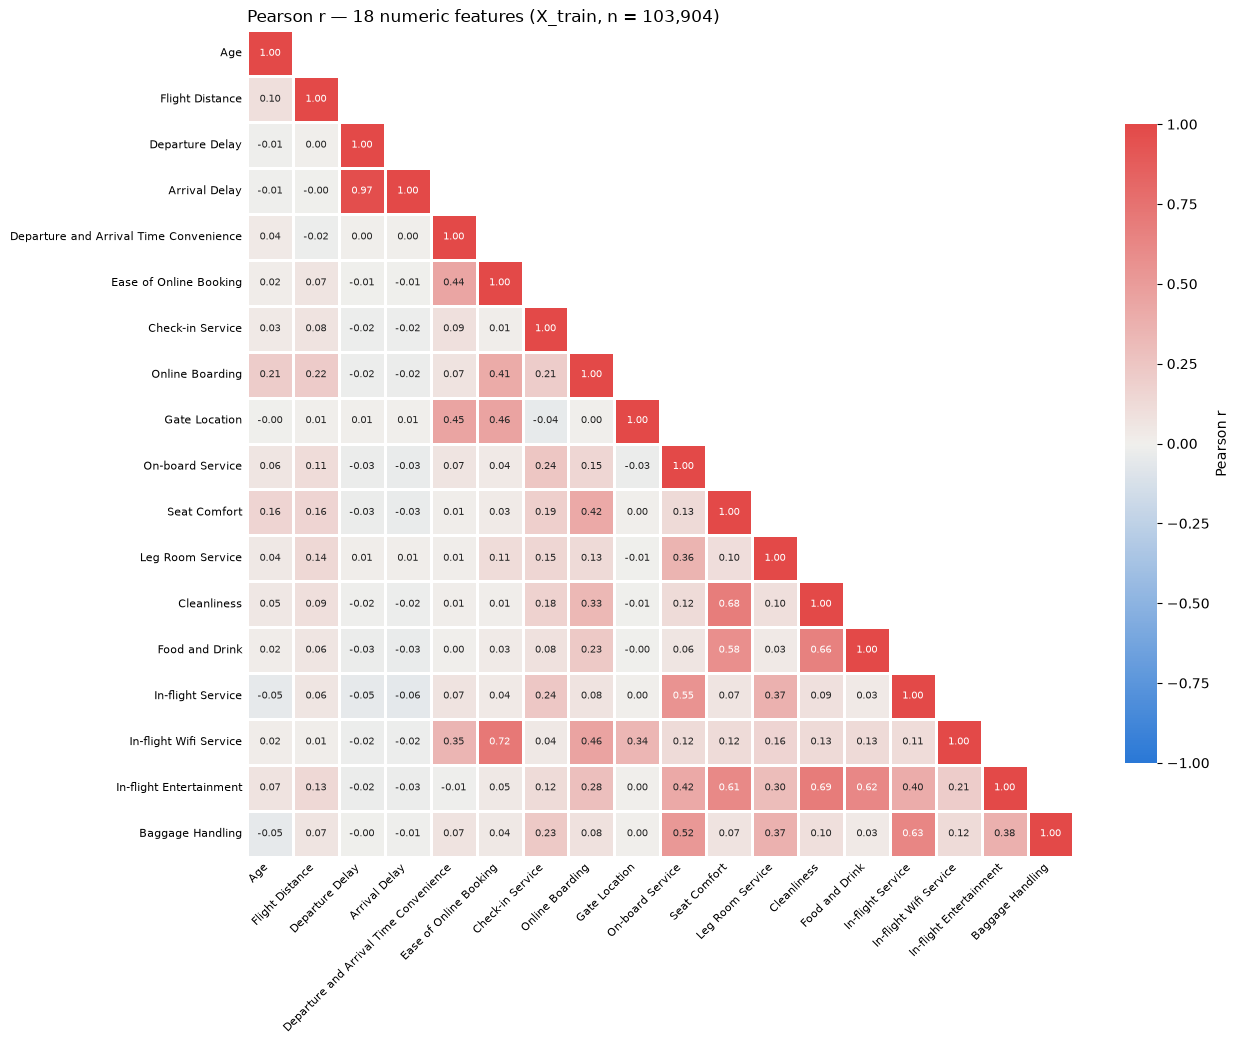

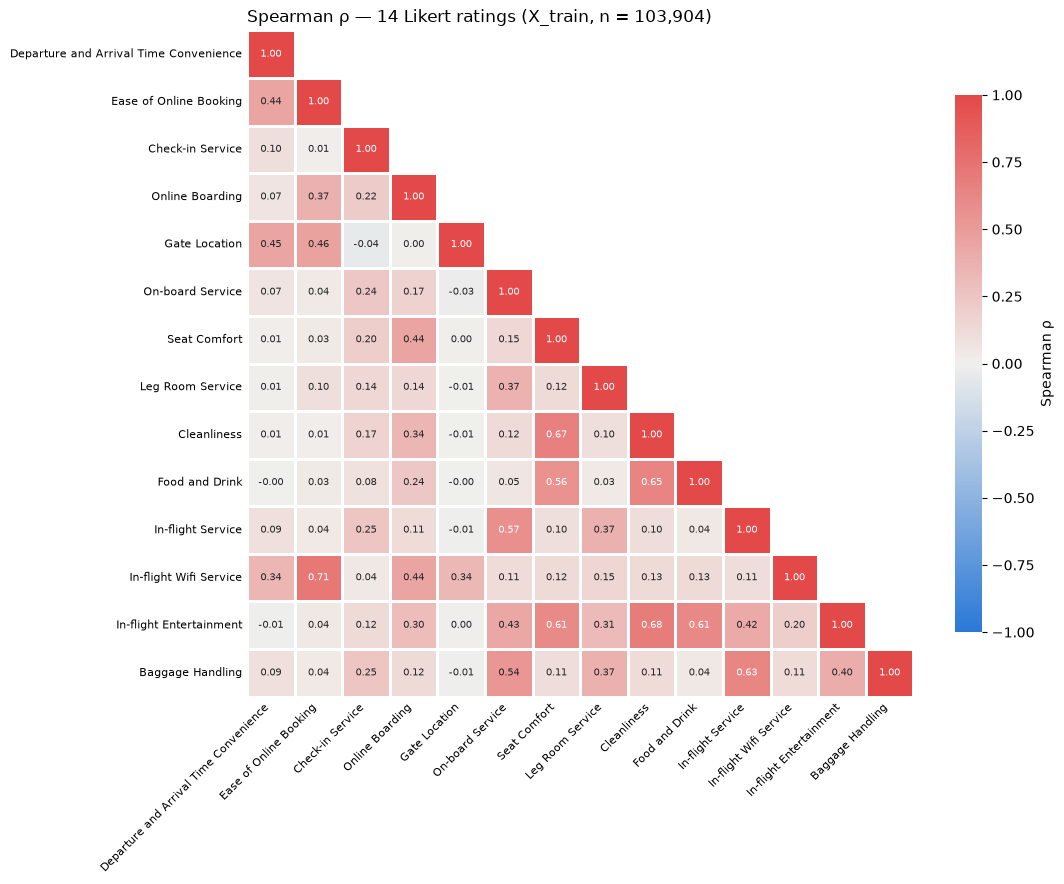

In [11]:
# 6a. Pearson (18 numerics) and Spearman (14 Likert, ordinal) correlation on X_train.
# pandas uses pairwise-complete rows, so the 321 NaNs in Arrival Delay are skipped, not imputed.
pearson = X_train[NUMERIC_COLS].corr(method="pearson")
spearman = X_train[NUMERIC_COLS].corr(method="spearman")

# Diverging blue <-> red with a neutral grey midpoint at r = 0
CORR_CMAP = LinearSegmentedColormap.from_list("corr_div", ["#2a78d6", "#f0efec", "#e34948"])


def plot_corr(r: pd.DataFrame, title: str, label: str, fname: str, figsize) -> None:
    mask = np.triu(np.ones_like(r, dtype=bool), k=1)  # lower triangle + diagonal
    fig, ax = plt.subplots(figsize=figsize)
    sns.heatmap(
        r, mask=mask, cmap=CORR_CMAP, vmin=-1, vmax=1, center=0,
        annot=True, fmt=".2f", annot_kws={"size": 7},
        linewidths=1, linecolor="white", square=True,
        cbar_kws={"label": label, "shrink": 0.7}, ax=ax,
    )
    ax.set_title(title, fontsize=12, loc="left")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)
    ax.tick_params(length=0)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=150, bbox_inches="tight")
    plt.show()


plot_corr(pearson, f"Pearson r — 18 numeric features (X_train, n = {len(X_train):,})",
          "Pearson r", "week2_corr_pearson_numeric.png", (13, 11))
plot_corr(spearman.loc[LIKERT_COLS, LIKERT_COLS],
          f"Spearman ρ — 14 Likert ratings (X_train, n = {len(X_train):,})",
          "Spearman ρ", "week2_corr_spearman_likert.png", (11, 9.5))

In [12]:
# 6b. Programmatic pair scan on the Pearson matrix (Spearman shown alongside)
iu = np.triu_indices(len(NUMERIC_COLS), k=1)
pairs = pd.DataFrame({
    "feature_1": pearson.columns[iu[0]],
    "feature_2": pearson.columns[iu[1]],
    "pearson_r": pearson.values[iu],
    "spearman_rho": spearman.values[iu],
})
pairs["|r|"] = pairs["pearson_r"].abs()
pairs["|rho - r|"] = (pairs["spearman_rho"] - pairs["pearson_r"]).abs()
pairs["both Likert"] = pairs["feature_1"].isin(LIKERT_COLS) & pairs["feature_2"].isin(LIKERT_COLS)
pairs = pairs.sort_values("|r|", ascending=False).reset_index(drop=True)

high = pairs[pairs["|r|"] > 0.90]
moderate = pairs[(pairs["|r|"] > 0.60) & (pairs["|r|"] <= 0.90)]
cols_show = ["feature_1", "feature_2", "pearson_r", "spearman_rho", "|rho - r|", "both Likert"]

print(f"Pairs with |r| > 0.90: {len(high)}")
display(high[cols_show].round(3))
print(f"Pairs with 0.60 < |r| <= 0.90: {len(moderate)} "
      f"({moderate['both Likert'].sum()} inside the Likert block)")
display(moderate[cols_show].round(3))
print(f"Max |Spearman - Pearson| over the moderate pairs: {moderate['|rho - r|'].max():.3f}")

top_likert = pairs[pairs["both Likert"]].iloc[0]
print(f"Strongest Likert pair: {top_likert['feature_1']} <-> {top_likert['feature_2']} "
      f"(r = {top_likert['pearson_r']:.3f}, rho = {top_likert['spearman_rho']:.3f})")

assert len(high) == 1 and set(high.iloc[0][["feature_1", "feature_2"]]) == {"Departure Delay", "Arrival Delay"}, \
    "expected exactly one |r| > 0.90 pair: Departure Delay <-> Arrival Delay"

Pairs with |r| > 0.90: 1


,feature_1,feature_2,pearson_r,spearman_rho,|rho - r|,both Likert
0,Departure Delay,Arrival Delay,0.966,0.739,0.227,False


Pairs with 0.60 < |r| <= 0.90: 7 (7 inside the Likert block)


,feature_1,feature_2,pearson_r,spearman_rho,|rho - r|,both Likert
1,Ease of Online Booking,In-flight Wifi Service,0.716,0.712,0.004,True
2,Cleanliness,In-flight Entertainment,0.693,0.682,0.011,True
3,Seat Comfort,Cleanliness,0.680,0.668,0.012,True
4,Cleanliness,Food and Drink,0.657,0.646,0.011,True
5,In-flight Service,Baggage Handling,0.630,0.631,0.001,True
6,Food and Drink,In-flight Entertainment,0.624,0.611,0.012,True
7,Seat Comfort,In-flight Entertainment,0.613,0.605,0.008,True


Max |Spearman - Pearson| over the moderate pairs: 0.012
Strongest Likert pair: Ease of Online Booking <-> In-flight Wifi Service (r = 0.716, rho = 0.712)


In [13]:
# 6c. Post-engineering check (spec §3.4.4) on the S2 matrix, built through a Pipeline on X_train
s2_pre = Pipeline([("preprocess", build_preprocessor(**STEP_KW["S2"]))]).fit(X_train, y_train)
X_s2 = s2_pre.transform(X_train)
r_s2 = X_s2.corr(method="pearson")
iu2 = np.triu_indices(r_s2.shape[0], k=1)
pairs_s2 = (pd.DataFrame({"feature_1": r_s2.index[iu2[0]], "feature_2": r_s2.columns[iu2[1]],
                          "pearson_r": r_s2.to_numpy()[iu2]})
            .assign(abs_r=lambda d: d["pearson_r"].abs())
            .sort_values("abs_r", ascending=False, ignore_index=True))
print(f"S2 matrix: {X_s2.shape[1]} columns; top 5 pairs by |r|:")
display(pairs_s2.head(5).round(3))
r_dep_net = r_s2.loc["log1p_Departure Delay", "Net Delay Recovery"]
print(f"log1p_Departure Delay <-> Net Delay Recovery: r = {r_dep_net:.3f}")
assert pairs_s2["abs_r"].max() <= 0.90, "a pair still exceeds |r| = 0.90 after engineering"
assert "Arrival Delay" not in X_s2.columns
print(f"Max |r| after engineering = {pairs_s2['abs_r'].max():.3f} <= 0.90 -> collinearity resolved")
del s2_pre, X_s2

S2 matrix: 22 columns; top 5 pairs by |r|:


,feature_1,feature_2,pearson_r,abs_r
0,Ease of Online Booking,In-flight Wifi Service,0.716,0.716
1,Cleanliness,In-flight Entertainment,0.693,0.693
2,Seat Comfort,Cleanliness,0.680,0.680
3,Cleanliness,Food and Drink,0.657,0.657
4,In-flight Service,Baggage Handling,0.630,0.630


log1p_Departure Delay <-> Net Delay Recovery: r = 0.312
Max |r| after engineering = 0.716 <= 0.90 -> collinearity resolved


### 6.1 Interpretation — Correlation decisions

**Pairs with |r| > 0.90 (Pearson, `X_train`).** The programmatic scan finds 1 pair: `Departure Delay` ↔ `Arrival Delay`, r = 0.966. No Likert pair comes close to the threshold.

**Pairs with 0.60 < |r| ≤ 0.90.** 7 pairs, all inside the Likert block. The strongest is `Ease of Online Booking` ↔ `In-flight Wifi Service` (Pearson 0.716, Spearman 0.712). Spearman values are within 0.012 of Pearson, so the ordinal scale does not change any decision.

| Pair | r (train, Pearson) | ρ (train, Spearman) | Decision | Reason |
|---|---|---|---|---|
| `Departure Delay` ↔ `Arrival Delay` | 0.966 | 0.739 | **Combine** into `Net Delay Recovery`, drop raw `Arrival Delay` | Keeps the in-flight recovery signal, removes redundancy |
| `Ease of Online Booking` ↔ `In-flight Wifi Service` | 0.716 | 0.712 | **Keep both** | Below 0.90; distinct digital touchpoints, so selection decides |
| `Cleanliness` ↔ `In-flight Entertainment` | 0.693 | 0.682 | **Keep both** | Below 0.90; RFECV removal candidate (SQ1) |
| `Seat Comfort` ↔ `Cleanliness` | 0.680 | 0.668 | **Keep both** | Below 0.90; RFECV removal candidate (SQ1) |
| `Cleanliness` ↔ `Food and Drink` | 0.657 | 0.646 | **Keep both** | Below 0.90 |
| `In-flight Service` ↔ `Baggage Handling` | 0.630 | 0.631 | **Keep both** | Below 0.90 |
| `Food and Drink` ↔ `In-flight Entertainment` | 0.624 | 0.611 | **Keep both** | Below 0.90 |
| `Seat Comfort` ↔ `In-flight Entertainment` | 0.613 | 0.605 | **Keep both** | Below 0.90 |

**Post-engineering check (S2 matrix).** The highest remaining pair is `Ease of Online Booking` ↔ `In-flight Wifi Service` at |r| = 0.716, so no pair exceeds 0.90 and raw `Arrival Delay` is gone. `log1p_Departure Delay` ↔ `Net Delay Recovery` is r = 0.312, which confirms the net feature is not a re-encoding of departure delay.

## 7. Ablation S0 — Baseline

In [14]:
# S0 baseline: raw 22 features, both collinear delays, median impute -> RobustScaler, OHE / ordinal, LR.
# Verdict rule (D10): Improved / Worsened only when |Δ| > max(paired fold std, MIN_EFFECT).
MIN_EFFECT = 0.001
log = AblationLog(base="S0")


def report(step):
    """One-line summary of a logged step (values used in the markdown write-ups)."""
    r = log.to_frame().set_index("step").loc[step]
    msg = (f"{step}: n={r.n_features} | ROC-AUC {r.roc_auc_mean:.4f} ± {r.roc_auc_std:.4f} | "
           f"PR-AUC {r.pr_auc_mean:.4f} ± {r.pr_auc_std:.4f} | F1 {r.f1_mean:.4f} ± {r.f1_std:.4f} | "
           f"train {r.train_roc_auc_mean:.4f} (gap {r.train_val_gap:+.4f}) | fit {r.fit_time_s:.2f} s")
    if pd.notna(r.delta_prev_roc_auc):
        thr = max(r.paired_delta_std, MIN_EFFECT)
        msg += (f"\n    vs {r.ref}: Δ ROC-AUC {r.delta_prev_roc_auc:+.5f} | paired std {r.paired_delta_std:.5f}"
                f" | threshold {thr:.5f} -> {r.verdict} | Δ vs S0 {r.delta_base_roc_auc:+.5f}")
    print(msg)


res_s0 = log.log_step("S0", "Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",
                      X_train, y_train, min_effect=MIN_EFFECT, return_estimator=True)
report("S0")
display(log.styled())

S0: n=22 | ROC-AUC 0.9256 ± 0.0017 | PR-AUC 0.9300 ± 0.0016 | F1 0.8513 ± 0.0028 | train 0.9256 (gap +0.0001) | fit 0.80 s


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc_mean,train_val_gap,ref,delta_prev_roc_auc,delta_base_roc_auc,paired_delta_std,fit_time_s,verdict
0,S0,"Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",22,0.9256,0.0017,0.9300,0.0016,0.8513,0.0028,0.9256,0.0001,—,—,—,—,0.80,Baseline


### 7.1 Interpretation — S0 Baseline

S0 fits LR on the raw 22 features (median impute → `RobustScaler`, OHE / ordinal) with both delay columns present, giving ROC-AUC **0.9256 ± 0.0017**, PR-AUC 0.9300 ± 0.0016 and F1 0.8513 ± 0.0028. The train ROC-AUC is 0.9256, a gap of +0.0001 to validation, so the linear baseline does not overfit. The score is already high because the Likert touchpoints carry most of the signal, so later steps are judged against fold noise rather than absolute size. **Verdict rule (decision D10):** a step is *Improved* / *Worsened* only when |Δ ROC-AUC| > max(paired fold std, 0.001); the 0.001 floor stops paired stds of order 1e-5 from turning negligible changes into verdicts. Fit time per fold is in the `report()` line above and is the reference for SQ1 latency (wall-clock, so it varies between runs).

## 8. Ablation S1, S1b, S2–S4

In [15]:
# S1 collinearity: replace raw Arrival Delay with Net Delay Recovery (net_median -> YJ -> Robust)
res_s1 = log.log_step("S1", "Combine delays into Net Delay Recovery, drop raw Arrival Delay",
                      X_train, y_train, min_effect=MIN_EFFECT, return_estimator=True)
report("S1")
display(log.styled())

# Coefficient stability across the 5 outer folds: S0 (both raw delays) vs S1 (Departure + Net)
coef_s0 = coef_std_across_folds(res_s0, ["Departure Delay", "Arrival Delay"]).assign(step="S0")
coef_s1 = coef_std_across_folds(res_s1, ["Departure Delay", "Net Delay Recovery"]).assign(step="S1")
display(pd.concat([coef_s0, coef_s1]).round(4))

S1: n=22 | ROC-AUC 0.9255 ± 0.0017 | PR-AUC 0.9299 ± 0.0016 | F1 0.8513 ± 0.0027 | train 0.9256 (gap +0.0001) | fit 0.90 s
    vs S0: Δ ROC-AUC -0.00007 | paired std 0.00004 | threshold 0.00100 -> Maintained | Δ vs S0 -0.00007


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc_mean,train_val_gap,ref,delta_prev_roc_auc,delta_base_roc_auc,paired_delta_std,fit_time_s,verdict
0,S0,"Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",22,0.9256,0.0017,0.9300,0.0016,0.8513,0.0028,0.9256,0.0001,—,—,—,—,0.80,Baseline
1,S1,"Combine delays into Net Delay Recovery, drop raw Arrival Delay",22,0.9255,0.0017,0.9299,0.0016,0.8513,0.0027,0.9256,0.0001,S0,-0.00007,-0.00007,0.00004,0.90,Maintained


,coef_mean,coef_std,step
Departure Delay,0.0444,0.0067,S0
Arrival Delay,-0.1108,0.0068,S0
Departure Delay,-0.0585,0.0022,S1
Net Delay Recovery,0.0172,0.0009,S1


### 8.1 Interpretation — S1 Collinearity (`Net Delay Recovery`)

S1 replaces raw `Arrival Delay` with `Net Delay Recovery` (`net_median` → Yeo-Johnson → `RobustScaler`). ROC-AUC moves from 0.9256 to 0.9255 (Δ = −0.00007 vs paired std 0.00004, threshold 0.001) → **Maintained**. The fold-to-fold std of the `Departure Delay` coefficient falls from 0.0067 (S0) to 0.0022 (S1), and its sign becomes sensible: in S0 it was **+0.044** (offset by −0.111 on `Arrival Delay`), while in S1 it is −0.059. This is expected: r = 0.966 inflates coefficient variance and makes the two coefficients cancel, but it adds no predictive power.

In [16]:
# S1b side branch: same as S1 but impute a missing Arrival Delay with its train median
res_s1b = log.log_step("S1b", "S1 with impute_strategy='arrival_median' (side branch)",
                       X_train, y_train, ref="S1", min_effect=MIN_EFFECT)
report("S1b")
display(log.styled())

# What each strategy imputes for the NaN-arrival rows of X_train (transformer fitted inside a Pipeline)
na_rows = X_train["Arrival Delay"].isna()
imputed = {s: Pipeline([("net", DelayFeatureEngineer(s))]).fit(X_train[cfg.DELAY_PAIR])
              .transform(X_train.loc[na_rows, cfg.DELAY_PAIR]).ravel()
           for s in ("net_median", "arrival_median")}
observed = (X_train["Departure Delay"] - X_train["Arrival Delay"]).dropna()
print(f"NaN-arrival train rows: {na_rows.sum()} | observed recovery range on train: "
      f"{observed.min():.0f} .. {observed.max():.0f} min")
for s, v in imputed.items():
    print(f"  {s:>14}: imputed recovery min {v.min():.0f}, max {v.max():.0f} min, "
          f"{(v > observed.max()).sum()} rows above the observed max")

S1b: n=22 | ROC-AUC 0.9255 ± 0.0017 | PR-AUC 0.9300 ± 0.0016 | F1 0.8513 ± 0.0029 | train 0.9256 (gap +0.0001) | fit 0.76 s
    vs S1: Δ ROC-AUC +0.00005 | paired std 0.00004 | threshold 0.00100 -> Maintained | Δ vs S0 -0.00002


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc_mean,train_val_gap,ref,delta_prev_roc_auc,delta_base_roc_auc,paired_delta_std,fit_time_s,verdict
0,S0,"Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",22,0.9256,0.0017,0.9300,0.0016,0.8513,0.0028,0.9256,0.0001,—,—,—,—,0.80,Baseline
1,S1,"Combine delays into Net Delay Recovery, drop raw Arrival Delay",22,0.9255,0.0017,0.9299,0.0016,0.8513,0.0027,0.9256,0.0001,S0,-0.00007,-0.00007,0.00004,0.90,Maintained
2,S1b,S1 with impute_strategy='arrival_median' (side branch),22,0.9255,0.0017,0.9300,0.0016,0.8513,0.0029,0.9256,0.0001,S1,+0.00005,-0.00002,0.00004,0.76,Maintained


NaN-arrival train rows: 321 | observed recovery range on train: -234 .. 54 min
      net_median: imputed recovery min 0, max 0 min, 0 rows above the observed max
  arrival_median: imputed recovery min 0, max 530 min, 83 rows above the observed max


### 8.2 Note — S1 vs S1b (imputation strategy)

With `arrival_median` imputation (S1b), ROC-AUC is 0.9255 vs 0.9255 for `net_median` (Δ = +0.00005, paired std 0.00004 → Maintained under the 0.001 floor). The real difference is in the imputed values: for the 321 NaN-arrival train rows, `arrival_median` imputes a recovery of up to **+530 min** (83 rows above the observed train max of +54 min), whereas `net_median` imputes 0 min for all of them. Because only 0.31% of rows are affected the score gap is negligible, so `net_median` is kept on domain grounds: it never produces recovery values outside the observed range.

In [17]:
# S2 skew: log1p on Flight Distance and Departure Delay (compared against S1, not the S1b side branch)
res_s2 = log.log_step("S2", "log1p on Flight Distance and Departure Delay",
                      X_train, y_train, ref="S1", min_effect=MIN_EFFECT)
report("S2")
d_s2 = log.to_frame().set_index("step").loc["S2", "delta_prev_roc_auc"]
print(f"    margin over the floor: Δ − MIN_EFFECT = {d_s2 - MIN_EFFECT:+.1e}  (borderline, see §8.3)")
display(log.styled())

S2: n=22 | ROC-AUC 0.9265 ± 0.0016 | PR-AUC 0.9305 ± 0.0015 | F1 0.8516 ± 0.0031 | train 0.9266 (gap +0.0001) | fit 0.75 s
    vs S1: Δ ROC-AUC +0.00100 | paired std 0.00019 | threshold 0.00100 -> Improved | Δ vs S0 +0.00093
    margin over the floor: Δ − MIN_EFFECT = +1.3e-06  (borderline, see §8.3)


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc_mean,train_val_gap,ref,delta_prev_roc_auc,delta_base_roc_auc,paired_delta_std,fit_time_s,verdict
0,S0,"Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",22,0.9256,0.0017,0.9300,0.0016,0.8513,0.0028,0.9256,0.0001,—,—,—,—,0.80,Baseline
1,S1,"Combine delays into Net Delay Recovery, drop raw Arrival Delay",22,0.9255,0.0017,0.9299,0.0016,0.8513,0.0027,0.9256,0.0001,S0,-0.00007,-0.00007,0.00004,0.90,Maintained
2,S1b,S1 with impute_strategy='arrival_median' (side branch),22,0.9255,0.0017,0.9300,0.0016,0.8513,0.0029,0.9256,0.0001,S1,+0.00005,-0.00002,0.00004,0.76,Maintained
3,S2,log1p on Flight Distance and Departure Delay,22,0.9265,0.0016,0.9305,0.0015,0.8516,0.0031,0.9266,0.0001,S1,+0.00100,+0.00093,0.00019,0.75,Improved


### 8.3 Interpretation — S2 Skew (`log1p`)

S2 applies `log1p` to `Flight Distance` and `Departure Delay`. ROC-AUC moves from 0.9255 (S1) to 0.9265 (Δ = +0.0010 vs paired std 0.00019). The log labels this **Improved**, but Δ sits **at** the 0.001 practical floor (the printed margin over the floor is of order 1e-6), so we report the gain as **borderline**. It is consistent across folds (the paired std is about a fifth of Δ), but PR-AUC (+0.0006) and F1 (+0.0003) are both below the floor, and a different BLAS or solver build could turn the verdict into *Maintained*. The floor was fixed before the ablation was run (D10) and is not moved after seeing this result. The direction still matches the hypothesis that the delay → log-odds response is concave, so compressing the tail helps a model that is linear in x; the effect is small because delays and distance are weak predictors next to the service ratings.

In [18]:
# S3 Likert flags: all 14 *_is_na flags, unfiltered (36 columns)
res_s3 = log.log_step("S3", "Add all 14 Likert *_is_na flags (unfiltered)",
                      X_train, y_train, min_effect=MIN_EFFECT, return_estimator=True)
report("S3")
display(log.styled())

flag_coefs = coef_std_across_folds(res_s3)
flag_coefs = (flag_coefs[flag_coefs.index.str.endswith("_is_na")]
              .assign(abs_coef=lambda d: d["coef_mean"].abs())
              .sort_values("abs_coef", ascending=False))
print("LR coefficients of the 14 flags (mean ± std over 5 outer folds):")
display(flag_coefs.round(3))

S3: n=36 | ROC-AUC 0.9648 ± 0.0004 | PR-AUC 0.9576 ± 0.0005 | F1 0.8876 ± 0.0016 | train 0.9648 (gap +0.0001) | fit 1.82 s
    vs S2: Δ ROC-AUC +0.03827 | paired std 0.00149 | threshold 0.00149 -> Improved | Δ vs S0 +0.03920


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc_mean,train_val_gap,ref,delta_prev_roc_auc,delta_base_roc_auc,paired_delta_std,fit_time_s,verdict
0,S0,"Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",22,0.9256,0.0017,0.9300,0.0016,0.8513,0.0028,0.9256,0.0001,—,—,—,—,0.80,Baseline
1,S1,"Combine delays into Net Delay Recovery, drop raw Arrival Delay",22,0.9255,0.0017,0.9299,0.0016,0.8513,0.0027,0.9256,0.0001,S0,-0.00007,-0.00007,0.00004,0.90,Maintained
2,S1b,S1 with impute_strategy='arrival_median' (side branch),22,0.9255,0.0017,0.9300,0.0016,0.8513,0.0029,0.9256,0.0001,S1,+0.00005,-0.00002,0.00004,0.76,Maintained
3,S2,log1p on Flight Distance and Departure Delay,22,0.9265,0.0016,0.9305,0.0015,0.8516,0.0031,0.9266,0.0001,S1,+0.00100,+0.00093,0.00019,0.75,Improved
4,S3,Add all 14 Likert *_is_na flags (unfiltered),36,0.9648,0.0004,0.9576,0.0005,0.8876,0.0016,0.9648,0.0001,S2,+0.03827,+0.03920,0.00149,1.82,Improved


LR coefficients of the 14 flags (mean ± std over 5 outer folds):


,coef_mean,coef_std,abs_coef
In-flight Wifi Service_is_na,11.189,0.250,11.189
Online Boarding_is_na,3.852,0.110,3.852
In-flight Entertainment_is_na,-2.032,0.158,2.032
Cleanliness_is_na,-1.998,0.148,1.998
Food and Drink_is_na,-1.959,0.119,1.959
Leg Room Service_is_na,1.081,0.179,1.081
Departure and Arrival Time Convenience_is_na,-0.840,0.042,0.840
Ease of Online Booking_is_na,0.581,0.158,0.581
On-board Service_is_na,-0.034,0.010,0.034
In-flight Service_is_na,-0.034,0.010,0.034


### 8.4 Interpretation — S3 Likert flags (all 14)

S3 adds all 14 `*_is_na` flags unfiltered (36 columns). ROC-AUC moves from 0.9265 to **0.9648** (Δ = +0.03827 vs paired std 0.00149) → **Improved**, the largest step in the ablation; PR-AUC rises 0.9305 → 0.9576 and F1 0.8516 → 0.8876. The largest absolute flag coefficients are `In-flight Wifi Service_is_na` (+11.19), `Online Boarding_is_na` (+3.85) and `In-flight Entertainment_is_na` (−2.03). This partly matches the hypothesis: the gain comes from Wifi and Online Boarding, but `Ease of Online Booking_is_na` is only +0.58. The third-ranked flag rests on 14 positive train rows, which is exactly the rare-flag instability that S4 removes. Separating "not applicable" from a low rating lets each rating's slope be fit on real 1–5 scores.

In [19]:
# S4 near-zero-variance filter: VarianceThreshold(0.0099) on the flag branch (26 columns)
res_s4 = log.log_step("S4", "VarianceThreshold(0.0099) on the flag branch (keeps 4 of 14)",
                      X_train, y_train, min_effect=MIN_EFFECT)
report("S4")
display(log.styled())

S4: n=26 | ROC-AUC 0.9646 ± 0.0004 | PR-AUC 0.9572 ± 0.0004 | F1 0.8876 ± 0.0017 | train 0.9647 (gap +0.0001) | fit 1.21 s
    vs S3: Δ ROC-AUC -0.00014 | paired std 0.00003 | threshold 0.00100 -> Maintained | Δ vs S0 +0.03906


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc_mean,train_val_gap,ref,delta_prev_roc_auc,delta_base_roc_auc,paired_delta_std,fit_time_s,verdict
0,S0,"Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",22,0.9256,0.0017,0.9300,0.0016,0.8513,0.0028,0.9256,0.0001,—,—,—,—,0.80,Baseline
1,S1,"Combine delays into Net Delay Recovery, drop raw Arrival Delay",22,0.9255,0.0017,0.9299,0.0016,0.8513,0.0027,0.9256,0.0001,S0,-0.00007,-0.00007,0.00004,0.90,Maintained
2,S1b,S1 with impute_strategy='arrival_median' (side branch),22,0.9255,0.0017,0.9300,0.0016,0.8513,0.0029,0.9256,0.0001,S1,+0.00005,-0.00002,0.00004,0.76,Maintained
3,S2,log1p on Flight Distance and Departure Delay,22,0.9265,0.0016,0.9305,0.0015,0.8516,0.0031,0.9266,0.0001,S1,+0.00100,+0.00093,0.00019,0.75,Improved
4,S3,Add all 14 Likert *_is_na flags (unfiltered),36,0.9648,0.0004,0.9576,0.0005,0.8876,0.0016,0.9648,0.0001,S2,+0.03827,+0.03920,0.00149,1.82,Improved
5,S4,VarianceThreshold(0.0099) on the flag branch (keeps 4 of 14),26,0.9646,0.0004,0.9572,0.0004,0.8876,0.0017,0.9647,0.0001,S3,-0.00014,+0.03906,0.00003,1.21,Maintained


### 8.5 Interpretation — S4 Near-zero-variance filter

S4 adds `VarianceThreshold(0.0099)` to the flag branch, cutting width from 36 to 26 columns. ROC-AUC moves from 0.9648 to 0.9646 (Δ = −0.00014 vs paired std 0.00003, threshold 0.001) → **Maintained**, and fit time per fold drops (compare the S3 and S4 `report()` lines; fit time is wall-clock, so the exact seconds vary between runs). The Δ is larger than the paired std, so a pure noise rule would call it a loss, but at 0.00014 ROC-AUC it is below the practical-significance floor. We accept it in exchange for 10 fewer columns and no coefficients fit on 0–474 positive rows, which confirms the §5 variance decisions with CV evidence.

## 9. Feature Selection — Method A vs Method B: Comparison, Stability & Decision

In [20]:
# 9a. Shared selection setup: S4 feature names, discrete-column mask for MI, inner CV
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
S4_NAMES = list(Pipeline([("preprocess", build_preprocessor())]).fit(X_train, y_train)
                .named_steps["preprocess"].get_feature_names_out())
DISCRETE_MASK = discrete_mask(S4_NAMES)
assert len(DISCRETE_MASK) == len(S4_NAMES) == 26 and DISCRETE_MASK.sum() == 22
score_func = make_mi_score_func(DISCRETE_MASK, n=20_000, random_state=RANDOM_STATE)
print(f"{len(S4_NAMES)} candidate features; {DISCRETE_MASK.sum()} marked discrete for MI: "
      f"3 OHE + Class + 14 Likert + 4 flags")
print("Continuous:", [n for n, d in zip(S4_NAMES, DISCRETE_MASK) if not d])

26 candidate features; 22 marked discrete for MI: 3 OHE + Class + 14 Likert + 4 flags
Continuous: ['Age', 'log1p_Flight Distance', 'log1p_Departure Delay', 'Net Delay Recovery']


S5a: n=20 | ROC-AUC 0.9620 ± 0.0006 | PR-AUC 0.9550 ± 0.0003 | F1 0.8838 ± 0.0014 | train 0.9621 (gap +0.0001) | fit 36.95 s
    vs S4: Δ ROC-AUC -0.00267 | paired std 0.00039 | threshold 0.00100 -> Worsened | Δ vs S0 +0.03639


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc_mean,train_val_gap,ref,delta_prev_roc_auc,delta_base_roc_auc,paired_delta_std,fit_time_s,verdict
0,S0,"Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",22,0.9256,0.0017,0.9300,0.0016,0.8513,0.0028,0.9256,0.0001,—,—,—,—,0.80,Baseline
1,S1,"Combine delays into Net Delay Recovery, drop raw Arrival Delay",22,0.9255,0.0017,0.9299,0.0016,0.8513,0.0027,0.9256,0.0001,S0,-0.00007,-0.00007,0.00004,0.90,Maintained
2,S1b,S1 with impute_strategy='arrival_median' (side branch),22,0.9255,0.0017,0.9300,0.0016,0.8513,0.0029,0.9256,0.0001,S1,+0.00005,-0.00002,0.00004,0.76,Maintained
3,S2,log1p on Flight Distance and Departure Delay,22,0.9265,0.0016,0.9305,0.0015,0.8516,0.0031,0.9266,0.0001,S1,+0.00100,+0.00093,0.00019,0.75,Improved
4,S3,Add all 14 Likert *_is_na flags (unfiltered),36,0.9648,0.0004,0.9576,0.0005,0.8876,0.0016,0.9648,0.0001,S2,+0.03827,+0.03920,0.00149,1.82,Improved
5,S4,VarianceThreshold(0.0099) on the flag branch (keeps 4 of 14),26,0.9646,0.0004,0.9572,0.0004,0.8876,0.0017,0.9647,0.0001,S3,-0.00014,+0.03906,0.00003,1.21,Maintained
6,S5a,"SelectKBest(MI), one-std k over [8, 10, 12, 14, 16, 18, 20]",20,0.9620,0.0006,0.9550,0.0003,0.8838,0.0014,0.9621,0.0001,S4,-0.00267,+0.03639,0.00039,36.95,Worsened


Full X_train: best k = 20 (inner ROC-AUC 0.9620 ± 0.0006); one-std threshold 0.9614 -> chosen k = 20
Outer-fold chosen k: [20, 20, 20, 20, 20]
Inner ROC-AUC by k (full X_train): k=8: 0.91052, k=10: 0.91302, k=12: 0.91384, k=14: 0.91432, k=16: 0.91597, k=18: 0.95987, k=20: 0.96196

MI ranking on full X_train (rank: feature, MI):
   1. Online Boarding                               0.2137
   2. In-flight Wifi Service                        0.1642
   3. Class                                         0.1344
   4. Type of Travel_Personal                       0.1135
   5. In-flight Entertainment                       0.0921
   6. Seat Comfort                                  0.0785
   7. Leg Room Service                              0.0632
   8. On-board Service                              0.0573
   9. log1p_Flight Distance                         0.0547
  10. Ease of Online Booking                        0.0514
  11. Cleanliness                                   0.0507
  12. Baggage Handlin

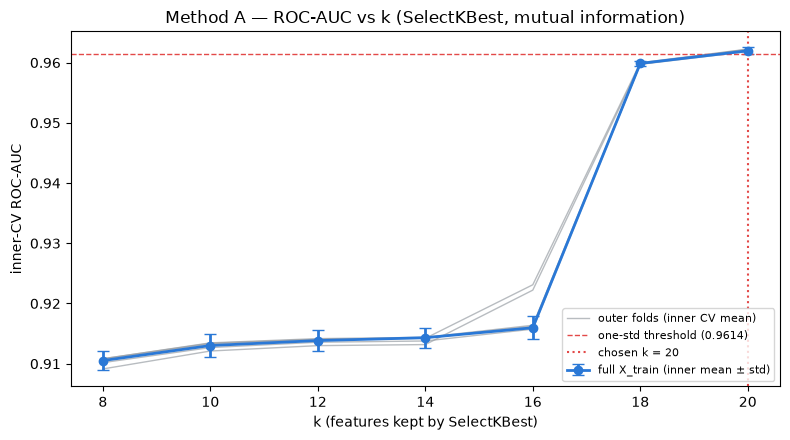

In [21]:
# 9b. Method A — SelectKBest(MI) with GridSearchCV over k (one-std refit), nested in the outer CV
search_a = make_selectkbest_search(score_func, inner_cv=inner_cv)
search_a_full = clone(search_a).fit(X_train, y_train)      # full-X_train fit -> lists + best k
k_a = int(search_a_full.best_params_["select__k"])
res_a = log.log_step("S5a", f"SelectKBest(MI), one-std k over {search_a.param_grid['select__k']}",
                     X_train, y_train, pipe=search_a, ref="S4", n_features=k_a,
                     min_effect=MIN_EFFECT, return_estimator=True)
report("S5a")
display(log.styled())

cvr = search_a_full.cv_results_
ks = np.array([p["select__k"] for p in cvr["params"]])
means, stds = cvr["mean_test_score"], cvr["std_test_score"]
best = int(np.argmax(means))
thr_a = means[best] - stds[best]
print(f"Full X_train: best k = {ks[best]} (inner ROC-AUC {means[best]:.4f} ± {stds[best]:.4f}); "
      f"one-std threshold {thr_a:.4f} -> chosen k = {k_a}")
print("Outer-fold chosen k:", [int(e.best_params_["select__k"]) for e in res_a["estimator"]])
print("Inner ROC-AUC by k (full X_train):", ", ".join(f"k={k}: {m:.5f}" for k, m in zip(ks, means)))

mi_scores = pd.Series(search_a_full.best_estimator_.named_steps["select"].scores_, index=S4_NAMES)
print("\nMI ranking on full X_train (rank: feature, MI):")
for i, (n, v) in enumerate(mi_scores.sort_values(ascending=False).items(), 1):
    print(f"  {i:>2}. {n:<45} {v:.4f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
for i, est in enumerate(res_a["estimator"]):
    ax.plot(ks, est.cv_results_["mean_test_score"], color="#9aa0a6", lw=1, alpha=0.7,
            label="outer folds (inner CV mean)" if i == 0 else None)
ax.errorbar(ks, means, yerr=stds, color="#2a78d6", marker="o", capsize=4, lw=2,
            label="full X_train (inner mean ± std)")
ax.axhline(thr_a, color="#e34948", ls="--", lw=1, label=f"one-std threshold ({thr_a:.4f})")
ax.axvline(k_a, color="#e34948", ls=":", lw=1.5, label=f"chosen k = {k_a}")
ax.set(xlabel="k (features kept by SelectKBest)", ylabel="inner-CV ROC-AUC", xticks=ks,
       title="Method A — ROC-AUC vs k (SelectKBest, mutual information)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "week2_selectkbest_auc_vs_k.png", dpi=150, bbox_inches="tight")
plt.show()

S5b: n=20 | ROC-AUC 0.9644 ± 0.0004 | PR-AUC 0.9569 ± 0.0003 | F1 0.8869 ± 0.0020 | train 0.9645 (gap +0.0001) | fit 31.07 s
    vs S4: Δ ROC-AUC -0.00018 | paired std 0.00008 | threshold 0.00100 -> Maintained | Δ vs S0 +0.03888


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc_mean,train_val_gap,ref,delta_prev_roc_auc,delta_base_roc_auc,paired_delta_std,fit_time_s,verdict
0,S0,"Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",22,0.9256,0.0017,0.9300,0.0016,0.8513,0.0028,0.9256,0.0001,—,—,—,—,0.80,Baseline
1,S1,"Combine delays into Net Delay Recovery, drop raw Arrival Delay",22,0.9255,0.0017,0.9299,0.0016,0.8513,0.0027,0.9256,0.0001,S0,-0.00007,-0.00007,0.00004,0.90,Maintained
2,S1b,S1 with impute_strategy='arrival_median' (side branch),22,0.9255,0.0017,0.9300,0.0016,0.8513,0.0029,0.9256,0.0001,S1,+0.00005,-0.00002,0.00004,0.76,Maintained
3,S2,log1p on Flight Distance and Departure Delay,22,0.9265,0.0016,0.9305,0.0015,0.8516,0.0031,0.9266,0.0001,S1,+0.00100,+0.00093,0.00019,0.75,Improved
4,S3,Add all 14 Likert *_is_na flags (unfiltered),36,0.9648,0.0004,0.9576,0.0005,0.8876,0.0016,0.9648,0.0001,S2,+0.03827,+0.03920,0.00149,1.82,Improved
5,S4,VarianceThreshold(0.0099) on the flag branch (keeps 4 of 14),26,0.9646,0.0004,0.9572,0.0004,0.8876,0.0017,0.9647,0.0001,S3,-0.00014,+0.03906,0.00003,1.21,Maintained
6,S5a,"SelectKBest(MI), one-std k over [8, 10, 12, 14, 16, 18, 20]",20,0.9620,0.0006,0.9550,0.0003,0.8838,0.0014,0.9621,0.0001,S4,-0.00267,+0.03639,0.00039,36.95,Worsened
7,S5b,"CappedRFECV(LR, step=1, max_features=20)",20,0.9644,0.0004,0.9569,0.0003,0.8869,0.0020,0.9645,0.0001,S4,-0.00018,+0.03888,0.00008,31.07,Maintained


Full X_train: uncapped optimum 26 -> selected 20 (capped: True)
Outer-fold selected n (uncapped): ['20 (26)', '20 (26)', '20 (26)', '20 (26)', '20 (26)']
Full X_train curve: best n = 26 (inner ROC-AUC 0.96464 ± 0.00035); one-std threshold 0.96429 -> one-std n = 19 (D11: reported, not applied)
Inner ROC-AUC by n (full X_train): n=16: 0.96180, n=17: 0.96220, n=18: 0.96351, n=19: 0.96444, n=20: 0.96445, n=21: 0.96447, n=22: 0.96447, n=23: 0.96446, n=24: 0.96447, n=25: 0.96448, n=26: 0.96464


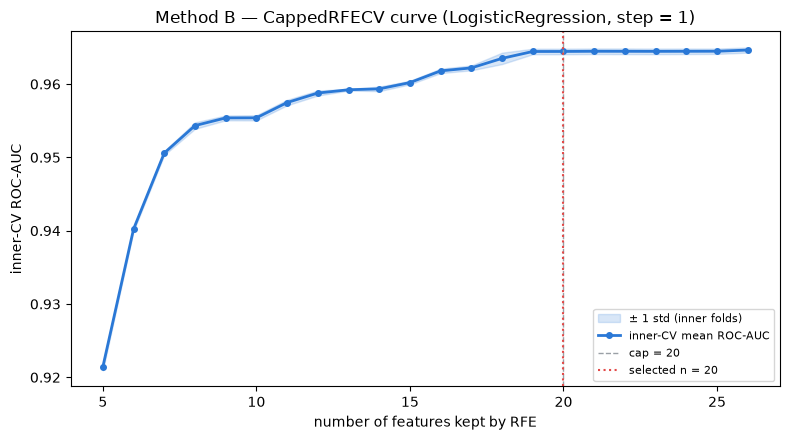

In [22]:
# 9c. Method B — CappedRFECV (LR, step=1, cap 20, same shuffled inner folds as A), nested in outer CV
rfe_template = CappedRFECV(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
                           max_features=20, step=1, min_features_to_select=5, cv=inner_cv,
                           scoring="roc_auc", n_jobs=1)
pipe_b = build_pipeline(rfe_template)
pipe_b_full = clone(pipe_b).fit(X_train, y_train)          # full-X_train fit -> lists + curve
rfe_full = pipe_b_full.named_steps["select"]
n_b = int(rfe_full.n_features_)
res_b = log.log_step("S5b", "CappedRFECV(LR, step=1, max_features=20)", X_train, y_train,
                     pipe=pipe_b, ref="S4", n_features=n_b, min_effect=MIN_EFFECT,
                     return_estimator=True)
report("S5b")
display(log.styled())

print(f"Full X_train: uncapped optimum {rfe_full.uncapped_n_features_} -> selected {n_b} "
      f"(capped: {rfe_full.capped_})")
print("Outer-fold selected n (uncapped):",
      [f"{e.named_steps['select'].n_features_} ({e.named_steps['select'].uncapped_n_features_})"
       for e in res_b["estimator"]])

rcv = rfe_full.cv_results_
n_feat, m_b, s_b = np.asarray(rcv["n_features"]), np.asarray(rcv["mean_test_score"]), np.asarray(rcv["std_test_score"])
# D11 check: what Method A's one-std rule would pick on B's curve (reported, not applied)
best_b = int(np.argmax(m_b))
thr_b = m_b[best_b] - s_b[best_b]
n_1se_b = int(n_feat[np.argmax(m_b >= thr_b)])          # smallest n at or above the threshold
print(f"Full X_train curve: best n = {n_feat[best_b]} (inner ROC-AUC {m_b[best_b]:.5f} ± {s_b[best_b]:.5f}); "
      f"one-std threshold {thr_b:.5f} -> one-std n = {n_1se_b} (D11: reported, not applied)")
print("Inner ROC-AUC by n (full X_train):",
      ", ".join(f"n={n}: {m:.5f}" for n, m in zip(n_feat, m_b) if n >= 16))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(n_feat, m_b - s_b, m_b + s_b, color="#2a78d6", alpha=0.18, label="± 1 std (inner folds)")
ax.plot(n_feat, m_b, color="#2a78d6", marker="o", ms=4, lw=2, label="inner-CV mean ROC-AUC")
ax.axvline(20, color="#9aa0a6", ls="--", lw=1, label="cap = 20")
ax.axvline(n_b, color="#e34948", ls=":", lw=1.5, label=f"selected n = {n_b}")
ax.set(xlabel="number of features kept by RFE", ylabel="inner-CV ROC-AUC",
       title="Method B — CappedRFECV curve (LogisticRegression, step = 1)")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "week2_rfecv_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [23]:
# 9d. Side-by-side comparison (lists from the full-X_train fits; scores from the nested outer CV)
sel_a = selected_features(search_a_full)
sel_b = selected_features(pipe_b_full)
jac = jaccard(sel_a, sel_b)
rows = []
for name, sel, res in (("A — SelectKBest (MI)", sel_a, res_a), ("B — CappedRFECV", sel_b, res_b)):
    rows.append({
        "method": name, "# selected": len(sel),
        "selected": ", ".join(sel), "removed": ", ".join(n for n in S4_NAMES if n not in sel),
        **{f"{lab}": f"{np.mean(res[f'test_{m}']):.4f} ± {np.std(res[f'test_{m}']):.4f}"
           for m, lab in (("roc_auc", "ROC-AUC"), ("pr_auc", "PR-AUC"), ("f1", "F1"))},
        "fit time / fold (s)": round(float(np.mean(res["fit_time"])), 1),
        "Jaccard (A, B)": round(jac, 3),
    })
comparison = pd.DataFrame(rows).set_index("method")
with pd.option_context("display.max_colwidth", None):
    display(comparison.drop(columns=["selected", "removed"]))
    display(comparison[["removed"]])
print("Selected by both :", sorted(set(sel_a) & set(sel_b)))
print("Only A           :", sorted(set(sel_a) - set(sel_b)))
print("Only B           :", sorted(set(sel_b) - set(sel_a)))

,# selected,ROC-AUC,PR-AUC,F1,fit time / fold (s),"Jaccard (A, B)"
method,,,,,,
A — SelectKBest (MI),20,0.9620 ± 0.0006,0.9550 ± 0.0003,0.8838 ± 0.0014,37.0,0.667
B — CappedRFECV,20,0.9644 ± 0.0004,0.9569 ± 0.0003,0.8869 ± 0.0020,31.1,0.667


,removed
method,
A — SelectKBest (MI),"Gender_Male, log1p_Departure Delay, Net Delay Recovery, Departure and Arrival Time Convenience, Departure and Arrival Time Convenience_is_na, Online Boarding_is_na"
B — CappedRFECV,"Gender_Male, Age, log1p_Flight Distance, Net Delay Recovery, Seat Comfort, Food and Drink"


Selected by both : ['Baggage Handling', 'Check-in Service', 'Class', 'Cleanliness', 'Customer Type_Returning', 'Ease of Online Booking', 'Ease of Online Booking_is_na', 'Gate Location', 'In-flight Entertainment', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Wifi Service_is_na', 'Leg Room Service', 'On-board Service', 'Online Boarding', 'Type of Travel_Personal']
Only A           : ['Age', 'Food and Drink', 'Seat Comfort', 'log1p_Flight Distance']
Only B           : ['Departure and Arrival Time Convenience', 'Departure and Arrival Time Convenience_is_na', 'Online Boarding_is_na', 'log1p_Departure Delay']


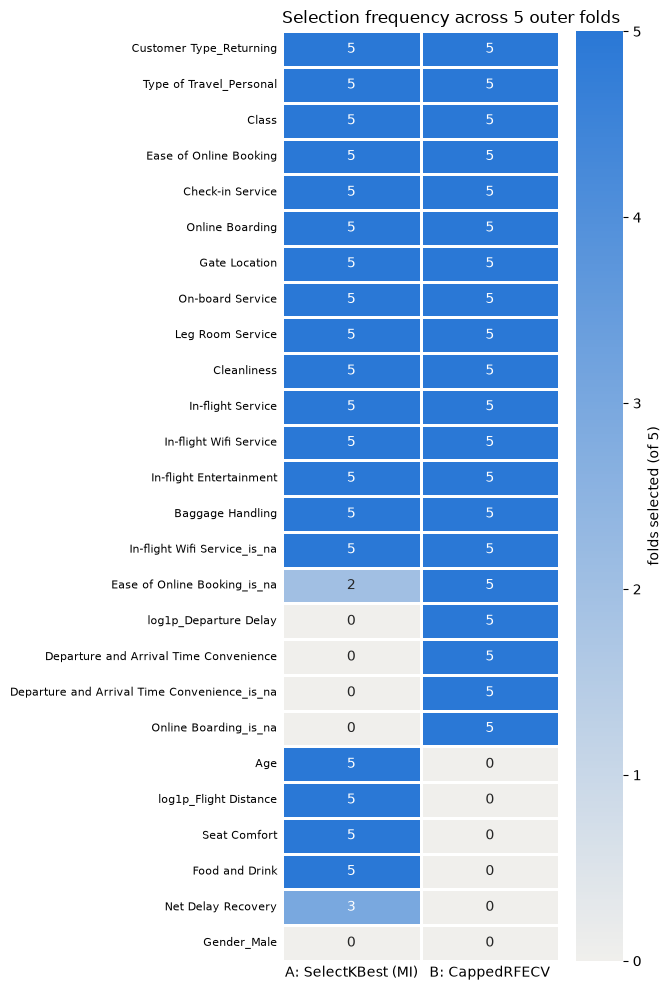

Selected in 5/5 folds by both methods (15): ['Customer Type_Returning', 'Type of Travel_Personal', 'Class', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Leg Room Service', 'Cleanliness', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling', 'In-flight Wifi Service_is_na']
Unstable under A: SelectKBest (MI) (1-4 folds): ['Ease of Online Booking_is_na', 'Net Delay Recovery']
Unstable under B: CappedRFECV (1-4 folds): []


In [24]:
# 9e. Stability: how often each feature is kept across the 5 outer folds (0-5)
freq = pd.DataFrame({
    "A: SelectKBest (MI)": selection_frequency(res_a["estimator"], S4_NAMES),
    "B: CappedRFECV": selection_frequency(res_b["estimator"], S4_NAMES),
}).sort_values(["B: CappedRFECV", "A: SelectKBest (MI)"], ascending=False)

fig, ax = plt.subplots(figsize=(6.5, 10))
sns.heatmap(freq, annot=True, fmt="d", cmap=LinearSegmentedColormap.from_list("freq", ["#f0efec", "#2a78d6"]),
            vmin=0, vmax=5, linewidths=1, linecolor="white", cbar_kws={"label": "folds selected (of 5)"}, ax=ax)
ax.set_title("Selection frequency across 5 outer folds", loc="left", fontsize=12)
ax.tick_params(length=0)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "week2_selection_stability.png", dpi=150, bbox_inches="tight")
plt.show()

both_stable = freq.index[(freq == 5).all(axis=1)].tolist()
unstable = {m: freq.index[(freq[m] > 0) & (freq[m] < 5)].tolist() for m in freq.columns}
print(f"Selected in 5/5 folds by both methods ({len(both_stable)}): {both_stable}")
for m, feats in unstable.items():
    print(f"Unstable under {m} (1-4 folds): {feats}")

In [25]:
# 9f. Decision rule (spec §3.5): ROC-AUC beyond max(paired std, MIN_EFFECT) -> fewer features -> CappedRFECV
winner, why = pick_winner(res_a, res_b, n_a=len(sel_a), n_b=len(sel_b), min_effect=MIN_EFFECT)
if winner == "A":
    FINAL_SELECTOR = SelectKBest(score_func, k=k_a)
    FINAL_FEATURES = sel_a
else:
    FINAL_SELECTOR = clone(rfe_full)          # unfitted twin: same params, refit inside final_pipe
    FINAL_FEATURES = sel_b
N_FINAL = len(FINAL_FEATURES)
assert N_FINAL <= 20, f"final selection has {N_FINAL} > 20 features"
print(f"Winner: Method {winner} -> {why}")
print(f"FINAL_SELECTOR = {FINAL_SELECTOR!r}")
print(f"N_final = {N_FINAL} <= 20")

Winner: Method B -> ROC-AUC delta(A-B)=-0.0025 beyond threshold 0.0010
FINAL_SELECTOR = CappedRFECV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
            estimator=LogisticRegression(max_iter=1000, random_state=42))
N_final = 20 <= 20


### 9.1 Interpretation — Feature selection: Method A vs Method B

**S5a — `SelectKBest(mutual_info_classif)`.** The one-std rule picks **k = 20** (best k = 20 at inner ROC-AUC 0.9620 ± 0.0006; threshold 0.9614), and every outer fold picks k = 20 as well. The chosen k therefore sits at the edge of the grid. Outer CV gives ROC-AUC 0.9620 ± 0.0006, so S5a is **Worsened** vs S4 (Δ = −0.00267, paired std 0.00039). The k-curve explains why. Marginal MI ranks `Customer Type_Returning` only 18th, although LR depends on it, so inner ROC-AUC jumps from 0.9160 (k = 16) to 0.9599 (k = 18) on full `X_train` (printed in 9b). MI also ranks `log1p_Departure Delay` and `Net Delay Recovery` 21st–22nd, so **Method A drops the engineered delay features** on full `X_train`. Ranked by marginal dependence, MI also keeps `Age`, `log1p_Flight Distance`, `Seat Comfort` and `Food and Drink`, and drops 2 of the 4 flags (`…Time Convenience_is_na`, `Online Boarding_is_na`) that LR uses conditionally.

**S5b — `CappedRFECV`.** Inner CV would keep all 26 features (uncapped optimum 26), so the cap applies and **20** are kept, in every outer fold. Outer CV gives ROC-AUC 0.9644 ± 0.0004, **Maintained** vs S4 (Δ = −0.00018, paired std 0.00008). The RFECV curve printed in 9c is flat from n = 19 to 26: n = 19–25 score 0.9644–0.9645 against the best 0.9646 ± 0.0004 at n = 26, so the last 7 features add almost nothing; n = 18 drops to 0.9635. The `|coef|` ranking reflects mixed scales (IQR-scaled continuous vs 0/1 flags), which favours the flags.

**Asymmetric rules (decision D11, closed).** A uses the one-std rule and B uses argmax under the cap. Both land on 20, so the "fewer features" tie-break never fires. Applying A's one-std rule to B's curve (9c) gives a threshold of 0.9643, which n = 18 misses and n = 19 meets, so B would keep **19** features against A's 20. The tie-break would then also favour B, and B already wins on rule 1 (below), so the asymmetry does not change the decision.

| Method | # selected | Selected | Removed | ROC-AUC | PR-AUC | F1 | Fit time / fold (s, wall-clock) | Jaccard |
|---|---|---|---|---|---|---|---|---|
| A — SelectKBest (MI) | 20 | 16 shared + `Age`, `log1p_Flight Distance`, `Seat Comfort`, `Food and Drink` | `Gender_Male`, `log1p_Departure Delay`, `Net Delay Recovery`, `Departure and Arrival Time Convenience`, `…Time Convenience_is_na`, `Online Boarding_is_na` | 0.9620 ± 0.0006 | 0.9550 ± 0.0003 | 0.8838 ± 0.0014 | see 9d | 0.667 |
| B — CappedRFECV | 20 | 16 shared + `log1p_Departure Delay`, `Departure and Arrival Time Convenience`, `…Time Convenience_is_na`, `Online Boarding_is_na` | `Gender_Male`, `Age`, `log1p_Flight Distance`, `Net Delay Recovery`, `Seat Comfort`, `Food and Drink` | 0.9644 ± 0.0004 | 0.9569 ± 0.0003 | 0.8869 ± 0.0020 | see 9d | 0.667 |

*16 shared:* `Customer Type_Returning`, `Type of Travel_Personal`, `Class`, 11 Likert ratings (all but `Departure and Arrival Time Convenience`, `Seat Comfort`, `Food and Drink`), `In-flight Wifi Service_is_na`, `Ease of Online Booking_is_na`.

**Stability.** 15 features are selected in all 5 outer folds by both methods, including `Customer Type_Returning`, `Type of Travel_Personal`, `Class`, `Online Boarding`, `In-flight Wifi Service` and `In-flight Wifi Service_is_na`. B is fully stable: every feature is kept in 0 or 5 folds. Under A, `Net Delay Recovery` (3/5) and `Ease of Online Booking_is_na` (2/5) are unstable. Together with B's flat curve from n = 19, these borderline features are the SQ1 candidates for removal with little loss. `Gender_Male` is dropped by both methods in every fold.

**Decision.** Rule 1: the ROC-AUC gap (A − B) is −0.0025, beyond max(paired std, 0.001) = 0.0010, so **B wins** without the tie-breaks. **`FINAL_SELECTOR` = `CappedRFECV(LogisticRegression(max_iter=1000, random_state=42), max_features=20, cv=inner_cv)`** with N = 20 ≤ 20 features. Note that the final set keeps `log1p_Departure Delay` but **not** `Net Delay Recovery`. The S1 step still did its job, since it removed the r = 0.966 collinearity and stabilised the delay coefficient, but once the flags are present, in-flight recovery adds no ROC-AUC that RFE can detect.

## 10. Dimensionality Reduction — PCA Statement, EVR Diagnostic & t-SNE

N_final = 20 <= 20 -> no predictive PCA (named features are needed for SQ2 SHAP).


PCA on the 20 selected features: PC1 explains 24.4%, PC1-2 39.5%; n_90 = 11 components reach 92.0%


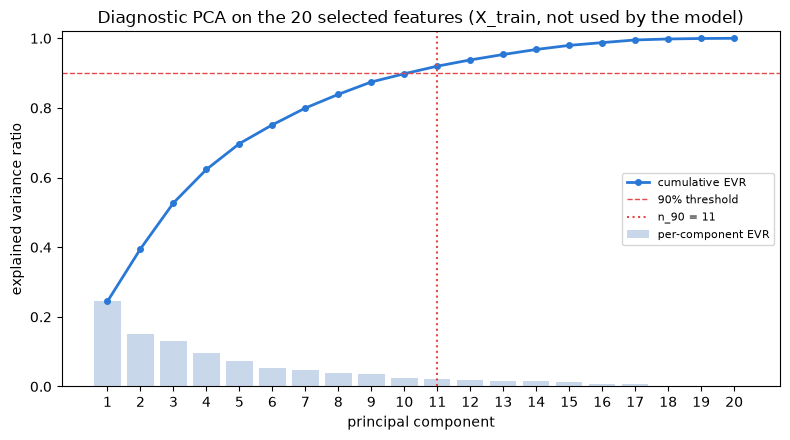

In [26]:
# 10a. Predictive PCA decision + diagnostic cumulative EVR (separate pipeline; nothing reaches the model)
print(f"N_final = {N_FINAL} <= 20 -> no predictive PCA (named features are needed for SQ2 SHAP).")
evr_pipe = Pipeline([("preprocess", build_preprocessor()),
                     ("select", clone(FINAL_SELECTOR)),
                     ("pca", PCA(random_state=RANDOM_STATE))]).fit(X_train, y_train)
evr = evr_pipe.named_steps["pca"].explained_variance_ratio_
cum = np.cumsum(evr)
n_90 = int(np.searchsorted(cum, 0.90) + 1)
print(f"PCA on the {len(evr)} selected features: PC1 explains {evr[0]:.1%}, PC1-2 {cum[1]:.1%}; "
      f"n_90 = {n_90} components reach {cum[n_90 - 1]:.1%}")

comps = np.arange(1, len(evr) + 1)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(comps, evr, color="#c9d7ea", label="per-component EVR")
ax.plot(comps, cum, color="#2a78d6", marker="o", ms=4, lw=2, label="cumulative EVR")
ax.axhline(0.90, color="#e34948", ls="--", lw=1, label="90% threshold")
ax.axvline(n_90, color="#e34948", ls=":", lw=1.5, label=f"n_90 = {n_90}")
ax.set(xlabel="principal component", ylabel="explained variance ratio", xticks=comps, ylim=(0, 1.02),
       title=f"Diagnostic PCA on the {len(evr)} selected features (X_train, not used by the model)")
ax.legend(loc="center right", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "week2_pca_cumulative_evr.png", dpi=150, bbox_inches="tight")
plt.show()

### 10.1 PCA statement & EVR diagnostic

**Predictive PCA is excluded.** N_final = 20 ≤ 20, so the pipeline is already compact. PCA would replace named features with orthogonal mixtures, which would break the named-feature SHAP analysis needed for SQ2 (business vs personal drivers) in Weeks 3–4.

**EVR diagnostic (not used by the model).** On the 20 selected features, PC1 alone explains 24.4% and PC1–2 39.5%. **n_90 = 11** components are needed to reach 90% (11 components give 92.0%). The selected features therefore share some variance, which is mostly the correlated in-flight Likert block from §6 (r 0.61–0.72). PCA could roughly halve the width, but every component would be a blend of ratings with no business meaning. Given ROC-AUC 0.9644 with 20 named features, that compression is not worth losing interpretability.

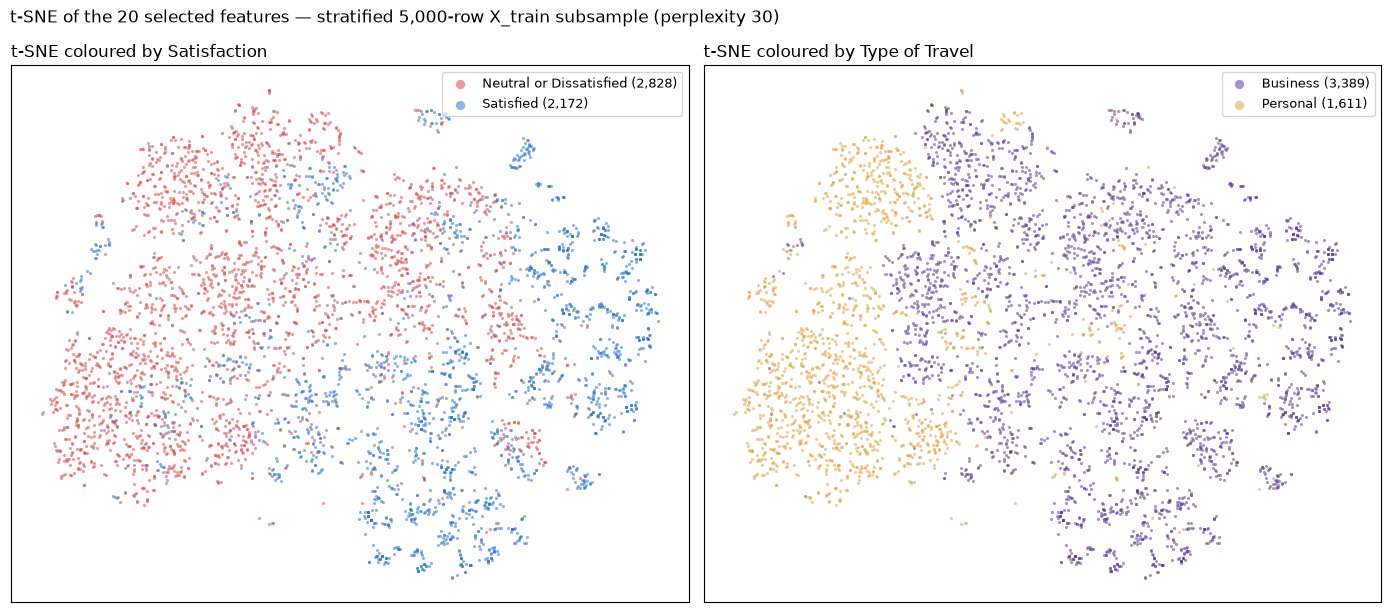

Satisfied rate by Type of Travel x Class in the subsample:


Class,Business,Economy,Economy Plus
Type of Travel,,,
Business,0.723,0.305,0.468
Personal,0.081,0.105,0.105


In [27]:
# 10b. 2D t-SNE: preprocessing + selection fitted on the full X_train, then transform-only on a
# stratified 5,000-row X_train subsample; t-SNE itself is wrapped in a Pipeline
tsne_prep = Pipeline([("preprocess", build_preprocessor()),
                      ("select", clone(FINAL_SELECTOR))]).fit(X_train, y_train)
X_sub, _, y_sub, _ = train_test_split(X_train, y_train, train_size=5_000, stratify=y_train,
                                      random_state=RANDOM_STATE)
X_sub_trans = tsne_prep.transform(X_sub)
Z_2d = Pipeline([("tsne", TSNE(n_components=2, perplexity=30, init="pca",
                               random_state=RANDOM_STATE))]).fit_transform(X_sub_trans)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharex=True, sharey=True)
panels = [
    (y_sub.map({0: "Neutral or Dissatisfied", 1: "Satisfied"}), "Satisfaction",
     {"Neutral or Dissatisfied": "#e34948", "Satisfied": "#2a78d6"}),
    (X_sub["Type of Travel"], "Type of Travel", {"Business": "#5b3fa3", "Personal": "#e8a33d"}),
]
for ax, (lab, title, pal) in zip(axes, panels):
    for level, color in pal.items():
        m = (lab == level).to_numpy()
        ax.scatter(Z_2d[m, 0], Z_2d[m, 1], s=5, alpha=0.55, color=color, label=f"{level} ({m.sum():,})",
                   linewidths=0)
    ax.set_title(f"t-SNE coloured by {title}", loc="left", fontsize=12)
    ax.set_xticks([]); ax.set_yticks([])
    ax.legend(markerscale=3, fontsize=9, loc="upper right", frameon=True)
fig.suptitle(f"t-SNE of the {X_sub_trans.shape[1]} selected features — stratified 5,000-row X_train "
             "subsample (perplexity 30)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
fig.savefig(FIG_DIR / "week2_tsne_2panel.png", dpi=150, bbox_inches="tight")
plt.show()

# Descriptive context for the write-up (pure counts on the subsample, no fitting)
print("Satisfied rate by Type of Travel x Class in the subsample:")
display(pd.crosstab([X_sub["Type of Travel"]], X_sub["Class"], values=y_sub, aggfunc="mean").round(3))

### 10.2 Interpretation — t-SNE (5,000-row stratified `X_train` subsample)

**Class separability.** In panel 1, `Neutral or Dissatisfied` passengers fill most of the left half of the map, and `Satisfied` passengers dominate the lower-right region and a set of small islands on the right edge. Large single-class areas therefore exist, which is consistent with the CV ROC-AUC of 0.9644 on these 20 features.

**Sub-clusters.** Panel 2 shows that `Type of Travel` splits the map into two main zones. Personal travellers form one compact block on the left, and Business travellers occupy the centre and right, broken into many small sub-clusters. The Personal block is almost entirely dissatisfied: in the subsample, only 8–11% of Personal travellers are satisfied in every class. Business travellers split by class and service ratings: 72% of Business travellers in Business class are satisfied, against 31% in Economy.

**Overlap.** The classes overlap mainly in the centre and upper-middle of the map. This is a Business-travel region where satisfied and dissatisfied points interleave, and passengers with mid-range ratings sit between the two groups. Most LR errors are expected here.

**Implications for Week 3.** The satisfied region is not one half-space. It is several sub-clusters whose satisfaction depends on `Type of Travel` × `Class` × service ratings. A linear model already does well (0.9644), but tree ensembles (Random Forest, gradient boosting) should gain from these interactions and from non-linear rating effects. Whether explicit interactions or one-hot Likert levels also help LR is a Week 3 question and is not claimed here. t-SNE preserves local neighbourhoods, not global distances, so cluster sizes and gaps are read qualitatively only.

## 11. Final Feature Set

In [28]:
# Final feature set (spec §3.5 step 4)
print(f"Selection rule: Method {winner} — {why}")
print(f"N_final = {N_FINAL} (cap 20)\n")
print("Kept:")
for i, n in enumerate(FINAL_FEATURES, 1):
    print(f"  {i:>2}. {n}")
print("\nRemoved from the 26 S4 columns:")
for n in S4_NAMES:
    if n not in FINAL_FEATURES:
        print(f"   - {n}")

Selection rule: Method B — ROC-AUC delta(A-B)=-0.0025 beyond threshold 0.0010
N_final = 20 (cap 20)

Kept:
   1. Customer Type_Returning
   2. Type of Travel_Personal
   3. Class
   4. log1p_Departure Delay
   5. Departure and Arrival Time Convenience
   6. Ease of Online Booking
   7. Check-in Service
   8. Online Boarding
   9. Gate Location
  10. On-board Service
  11. Leg Room Service
  12. Cleanliness
  13. In-flight Service
  14. In-flight Wifi Service
  15. In-flight Entertainment
  16. Baggage Handling
  17. Departure and Arrival Time Convenience_is_na
  18. Ease of Online Booking_is_na
  19. Online Boarding_is_na
  20. In-flight Wifi Service_is_na

Removed from the 26 S4 columns:
   - Gender_Male
   - Age
   - log1p_Flight Distance
   - Net Delay Recovery
   - Seat Comfort
   - Food and Drink


## 12. Ablation Log Export

Deltas and the paired std are shown to 5 d.p. so that stds of order 1e-5 and Δ values at the 0.001 floor are not rounded away. Export the PDF with `jupyter nbconvert --to webpdf` so the styled tables render; the LaTeX `--to pdf` route falls back to the same table as plain text.

In [29]:
# Export the ablation log (fit_time_s is wall-clock and is not expected to reproduce exactly)
LOG_PATH = ROOT / "reports" / "week2_cv_log.csv"
cv_log = log.to_csv(LOG_PATH)
print(f"Saved {len(cv_log)} rows -> {LOG_PATH.relative_to(ROOT)}")
display(log.styled())

Saved 8 rows -> reports\week2_cv_log.csv


,step,description,n_features,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,f1_mean,f1_std,train_roc_auc_mean,train_val_gap,ref,delta_prev_roc_auc,delta_base_roc_auc,paired_delta_std,fit_time_s,verdict
0,S0,"Baseline: raw 22 features (both delays), impute + RobustScaler, OHE/ordinal",22,0.9256,0.0017,0.9300,0.0016,0.8513,0.0028,0.9256,0.0001,—,—,—,—,0.80,Baseline
1,S1,"Combine delays into Net Delay Recovery, drop raw Arrival Delay",22,0.9255,0.0017,0.9299,0.0016,0.8513,0.0027,0.9256,0.0001,S0,-0.00007,-0.00007,0.00004,0.90,Maintained
2,S1b,S1 with impute_strategy='arrival_median' (side branch),22,0.9255,0.0017,0.9300,0.0016,0.8513,0.0029,0.9256,0.0001,S1,+0.00005,-0.00002,0.00004,0.76,Maintained
3,S2,log1p on Flight Distance and Departure Delay,22,0.9265,0.0016,0.9305,0.0015,0.8516,0.0031,0.9266,0.0001,S1,+0.00100,+0.00093,0.00019,0.75,Improved
4,S3,Add all 14 Likert *_is_na flags (unfiltered),36,0.9648,0.0004,0.9576,0.0005,0.8876,0.0016,0.9648,0.0001,S2,+0.03827,+0.03920,0.00149,1.82,Improved
5,S4,VarianceThreshold(0.0099) on the flag branch (keeps 4 of 14),26,0.9646,0.0004,0.9572,0.0004,0.8876,0.0017,0.9647,0.0001,S3,-0.00014,+0.03906,0.00003,1.21,Maintained
6,S5a,"SelectKBest(MI), one-std k over [8, 10, 12, 14, 16, 18, 20]",20,0.9620,0.0006,0.9550,0.0003,0.8838,0.0014,0.9621,0.0001,S4,-0.00267,+0.03639,0.00039,36.95,Worsened
7,S5b,"CappedRFECV(LR, step=1, max_features=20)",20,0.9644,0.0004,0.9569,0.0003,0.8869,0.0020,0.9645,0.0001,S4,-0.00018,+0.03888,0.00008,31.07,Maintained


## 13. Final Pipeline — Fit, Transform & Predict

In [30]:
# FINAL CELL — the first and only use of X_test
from sklearn import set_config

final_pipe = build_pipeline(selector=clone(FINAL_SELECTOR))
final_pipe.fit(X_train, y_train)

Xt_train = final_pipe[:-1].transform(X_train)
Xt_test = final_pipe[:-1].transform(X_test)
print(f"X_train raw {X_train.shape} -> transformed {Xt_train.shape}")
print(f"X_test  raw {X_test.shape} -> transformed {Xt_test.shape}")
assert Xt_train.shape[1] == Xt_test.shape[1] <= 20

y_pred = final_pipe.predict(X_test)
print(f"y_pred.shape = {y_pred.shape}")
final_names = selected_features(final_pipe)
assert final_names == FINAL_FEATURES
print(f"Selected features ({len(final_names)}): {final_names}")

proba = final_pipe.predict_proba(X_test)
print(f"Test ROC-AUC (sanity check only, never used for selection): {roc_auc_score(y_test, proba[:, 1]):.4f}")

buf = io.BytesIO()
joblib.dump(final_pipe, buf)
buf.seek(0)
reloaded = joblib.load(buf)
assert np.allclose(reloaded.predict_proba(X_test), proba)
print(f"joblib round-trip ({buf.getbuffer().nbytes / 1024:.0f} KiB): predict_proba identical")

set_config(display="diagram")
final_pipe

X_train raw (103904, 22) -> transformed (103904, 20)
X_test  raw (25976, 22) -> transformed (25976, 20)
y_pred.shape = (25976,)
Selected features (20): ['Customer Type_Returning', 'Type of Travel_Personal', 'Class', 'log1p_Departure Delay', 'Departure and Arrival Time Convenience', 'Ease of Online Booking', 'Check-in Service', 'Online Boarding', 'Gate Location', 'On-board Service', 'Leg Room Service', 'Cleanliness', 'In-flight Service', 'In-flight Wifi Service', 'In-flight Entertainment', 'Baggage Handling', 'Departure and Arrival Time Convenience_is_na', 'Ease of Online Booking_is_na', 'Online Boarding_is_na', 'In-flight Wifi Service_is_na']
Test ROC-AUC (sanity check only, never used for selection): 0.9657


joblib round-trip (43 KiB): predict_proba identical


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('select', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['Gender','Age','Customer Type',...,'In-flight Wifi Service', 'In-flight Entertainment','Baggage Handling']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('nominal', ...), ('class_ord', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that